# Regression Under Increasing Uncertainty

Three analytical functions, a synthetic multivariate dataset and eighty years
of wartime weather readings, used to ask one question: when do regression
models deserve to be trusted?

The order matters. The first experiments fit curves whose formula is written
down, so "did the model recover the truth" is literally checkable. Noise is
then added, then correlated and irrelevant features, and finally the ground
truth is removed altogether by forecasting temperatures that no equation
describes. Each step takes away a little more certainty and asks the same
models to cope.

Linear and polynomial regression, ridge, Bayesian ridge, random forest,
gradient boosting and SVR are scored throughout on R squared and mean squared
error, with `TimeSeriesSplit` and `GridSearchCV` used once the data becomes a
time series.


## Libraries


In [1]:
# Basic libraries
import numpy as np
import pandas as pd
from IPython.display import display, Math
import random
import os

# Visualization
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, BayesianRidge
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from scipy.signal import savgol_filter
from sklearn.feature_selection import SelectKBest, f_regression

# For synthetic data generation
from sklearn.datasets import make_regression

#For table generations
!pip install tabulate colorama -q

from tabulate import tabulate
from colorama import Fore, Style, init
init(autoreset=True)


# To download and manage real dataset
!pip install wget -q
import wget

# For datetime handling
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\OO\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


[notice] A new release of pip is available: 26.1.1 -> 26.2.1

[notice] To update, run: C:\Users\OO\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip

All libraries imported successfully!

## The data


### Synthetic data

In this section, we generate and analyze **synthetic datasets** to explore how different regression models perform on known functional relationships. This helps in  understanding model behavior in controlled conditions before applying them to real-world data.

> 💡 **Why use synthetic data?**
>  
> Synthetic datasets allow us to test machine learning algorithms in a controlled environment. By knowing the underlying patterns (e.g., functions or distributions), we can better evaluate whether our models are learning effectively and generalizing well.

---

### 📘 Functions Used for Univariate Dataset Generation

I generated data for the following three functions:

1. $ f_1(x) = x \cdot \sin(x) + 2x $ 🌀  
2. $ f_2(x) = 10 \cdot \sin(x) + x^2 $ 🌊  
3. $ f_3(x) = \text{sign}(x)(x^2 + 300) + 20 \cdot \sin(x) $ 🧩  

#### 🔍 Input Range & Sampling:
- $ x \in [-20, 20] $
- 100 samples per function
- Split into: **70% train / 30% test**

---

### Multivariate data with `make_regression`

Automatically generated using scikit-learn’s `make_regression` function — ideal for testing multivariate regression pipelines.

<details>
<summary>📘 Click to expand details</summary>

### Generating the univariate sets

```python
# Set parameters
tr = 20
n_samples = 100

# Define functions
def f1(x): return x * np.sin(x) + 2 * x
def f2(x): return 10 * np.sin(x) + x**2
def f3(x): return np.sign(x) * (x**2 + 300) + 20 * np.sin(x)

# Generate input data
X = np.linspace(-tr, tr, n_samples)

# Generate outputs
y1 = f1(X)
y2 = f2(X)
y3 = f3(X)

# Split data into train and test sets
def split_data(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=0.7, random_state=42, shuffle=True
    )
    sorted_indices = np.argsort(X_test)
    return X_train, X_test[sorted_indices], y_train, y_test[sorted_indices]

X_train_f1, X_test_f1, y_train_f1, y_test_f1 = split_data(X, y1)
X_train_f2, X_test_f2, y_train_f2, y_test_f2 = split_data(X, y2)
X_train_f3, X_test_f3, y_train_f3, y_test_f3 = split_data(X, y3)

print("✅ Three synthetic datasets generated and split.")
```

### 📈 Visualizing the Functions

```python
def plot_function(X_test, y_test, title):
    plt.figure(figsize=(8, 4))
    plt.scatter(X_test, y_test, label="True Function", alpha=0.6)
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_function(X_test_f1, y_test_f1, "f1(x) = x·sin(x) + 2x")
plot_function(X_test_f2, y_test_f2, "f2(x) = 10·sin(x) + x²")
plot_function(X_test_f3, y_test_f3, "f3(x) = sign(x)(x² + 300) + 20·sin(x)")
```

### 📊 Running Evaluation on Each Function

```python
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=3)": make_pipeline(PolynomialFeatures(degree=3), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(kernel='rbf')
}

def train_and_evaluate(X_train, X_test, y_train, y_test, title):
    plt.figure(figsize=(12, 6))
    plt.scatter(X_test, y_test, label="True Function", color="black", alpha=0.5)

    for name, model in models.items():
        try:
            model.fit(X_train.reshape(-1, 1), y_train)
            y_pred = model.predict(X_test.reshape(-1, 1))
            r2 = r2_score(y_test, y_pred)
            mse = mean_squared_error(y_test, y_pred)
            print(f"{title} - {name}: R²={r2:.3f}, MSE={mse:.3f}")
            plt.plot(X_test, y_pred, label=f"{name} (R²={r2:.2f})")
        except Exception as e:
            print(f"Error with {name}: {e}")

    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)
    plt.show()

train_and_evaluate(X_train_f1, X_test_f1, y_train_f1, y_test_f1, "f1(x) = x·sin(x) + 2x")
train_and_evaluate(X_train_f2, X_test_f2, y_train_f2, y_test_f2, "f2(x) = 10·sin(x) + x²")
train_and_evaluate(X_train_f3, X_test_f3, y_train_f3, y_test_f3, "f3(x) = sign(x)(x² + 300) + 20·sin(x)")
```

### Generating the multivariate set

```python
from sklearn.datasets import make_regression

X_multi, y_multi = make_regression(
    n_samples=2000,
    n_features=10,
    n_informative=5,
    noise=10,
    random_state=42
)

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, train_size=0.7, random_state=42
)

print("✅ Multivariate synthetic dataset generated and split.")
```

### 🧱 Multivariate Regression on Synthetic Data

```python
def train_and_evaluate_multivariate(X_train, X_test, y_train, y_test):
    results = []
    for name, model in models.items():
        if name == "SVR":
            continue
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        results.append((name, r2, mse))
        print(f"{name}: R²={r2:.3f}, MSE={mse:.3f}")
    return results

print("Multivariate Dataset Results:")
train_and_evaluate_multivariate(X_train_multi, X_test_multi, y_train_multi, y_test_multi)
print("✅ Multivariate synthetic dataset generated and split.")

```
</details>

### Second World War temperature readings

This is a real-world dataset, sourced from NOAA and hosted on Kaggle, contains **daily weather measurements** recorded during **World War II (1940–1945)** from **159 global weather stations**.

#### 🔑 Key Features:
- **📅 Time Range**: 1940-01-01 to 1945-12-31  
- **📦 Total Records**: 119,040  
- **🌡️ Measured Variables**:
  - `STA`: Station ID  
  - `Date`: Recording date  
  - `MinTemp`, `MeanTemp`, `MaxTemp`: Daily temperatures in °C  
  - `Precipitation`: Rainfall in mm  

#### 📍 Focused Sensor:
Analysis focused on data from **sensor 22508**, located in **Honolulu, Hawaii** (`Lat: 21.4833`, `Lon: -158.05`), which provides a relatively complete temperature time series.

> ⚠️ Note: Many sensors have missing values; so we focused on sensor 22508 for simplicity and consistency.

🔗 [Dataset Link](https://www.kaggle.com/datasets/smid80/weatherww2 )

<details>
<summary>📘 Click to expand details</summary>

### ➕ Download & Unzip Dataset
```python
# Step 1: Download the zip file
!wget -q https://github.com/dbdmg/data-science-lab/raw/master/datasets/weatherww2.zip

# Step 2: Unzip the file
!unzip weatherww2.zip

# Step 3: List files to confirm we have the CSVs
!ls
```
</details>

## The experiments

## Approximating known functions

Three analytical functions are the ground truth here. Because each one is
written down, every model can be scored on how closely it recovers a curve
whose shape is already known, and hyperparameters can be tuned against that
same standard.

**📐 Target Functions**

- **f1(x) = x * sin(x) + 2x**
- **f2(x) = 10 * sin(x) + x²**
- **f3(x) = sign(x) * (x² + 300) + 20 * sin(x)**



**🔢 Step 1: Generating  Synthetic Data for f1(x)**

📌 Function 1:

**f1(x) = x * sin(x) + 2x**


In [2]:
# Parameters
tr = 20
n_samples = 100

# Define function
def f1(x):
    return x * np.sin(x) + 2 * x

# Generate input data
X = np.linspace(-tr, tr, n_samples)

# Generate output data
y = f1(X)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42, shuffle=True
)

# Sort test set for plotting
X_test.sort()
y_test = f1(X_test) # FIX: Recompute y_test from sorted X_test

📈 **Step 2: Visualizing the Function**

This helps understand fn's shape and choose an appropriate regression method.

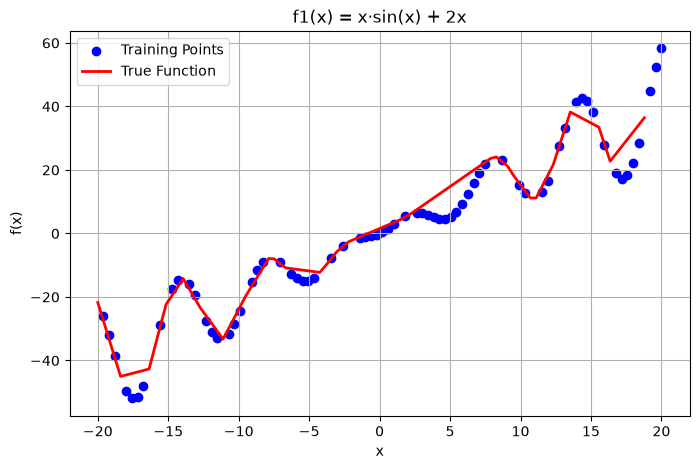

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='Training Points', color='blue')
plt.plot(X_test, y_test, 'r-', lw=2, label='True Function')
plt.title("f1(x) = x·sin(x) + 2x")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True)
plt.show()

**What the shape predicts**

The curve is strongly non-linear, which sets expectations before anything is
fitted. Polynomial regression should capture the curvature. Random forest and
SVR are plausible too, since neither assumes a straight line. Plain linear
regression should struggle, and that expectation is worth recording now so the
scores can confirm or contradict it.


**🤖 Step 3: Train Multiple Regression Models**

Training and comparing several models

Used two main metrics from sklearn.metrics:



*   r2_score: to measure how well the model explains the variance in the target.
*   mean_squared_error: to measure the average squared difference between predicted and actual values.




In [4]:
# Set seed
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Parameters
tr = 20
n_samples = 100

# Define function
def f1(x):
    return x * np.sin(x) + 2 * x

# Generate input and output data
X = np.linspace(-tr, tr, n_samples)
y = f1(X)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42, shuffle=True
)

# Sort test set for plotting
sorted_idx = np.argsort(X_test)
X_test = X_test[sorted_idx]
y_test = y_test[sorted_idx]

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=3)": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
}

# Train and evaluate
results = {}
for name, model in models.items():
    # Apply scaling only to Linear and Polynomial Regression
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train.reshape(-1, 1))
        X_test_scaled = scaler.transform(X_test.reshape(-1, 1))
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        # Tree-based models: no scaling needed
        model.fit(X_train.reshape(-1, 1), y_train)
        y_pred = model.predict(X_test.reshape(-1, 1))

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    results[name] = (r2, mse)

# Prepare data for tabulate
table_data = []
for idx, (name, (r2, mse)) in enumerate(results.items()):
    table_data.append([idx+1, name, f"{r2:.3f}", f"{mse:.3f}"])

# Print with color and table formatting
print(Fore.CYAN + "\n Model Evaluation Results:"+ Style.RESET_ALL)
print(tabulate(table_data, headers=["#", "Model", "R² Score", "MSE"], tablefmt="grid"))


 Model Evaluation Results:

+-----+-------------------------------+------------+--------+
|   # | Model                         |   R² Score |    MSE |
+=====+===============================+============+========+
|   1 | Linear Regression             |      0.892 | 57.42  |
+-----+-------------------------------+------------+--------+
|   2 | Polynomial Regression (deg=3) |      0.891 | 58.038 |
+-----+-------------------------------+------------+--------+
|   3 | Random Forest                 |      0.987 |  7.01  |
+-----+-------------------------------+------------+--------+
|   4 | SVR (RBF Kernel)              |      0.885 | 60.914 |
+-----+-------------------------------+------------+--------+

**📊 Plotting Predictions vs True Function:**

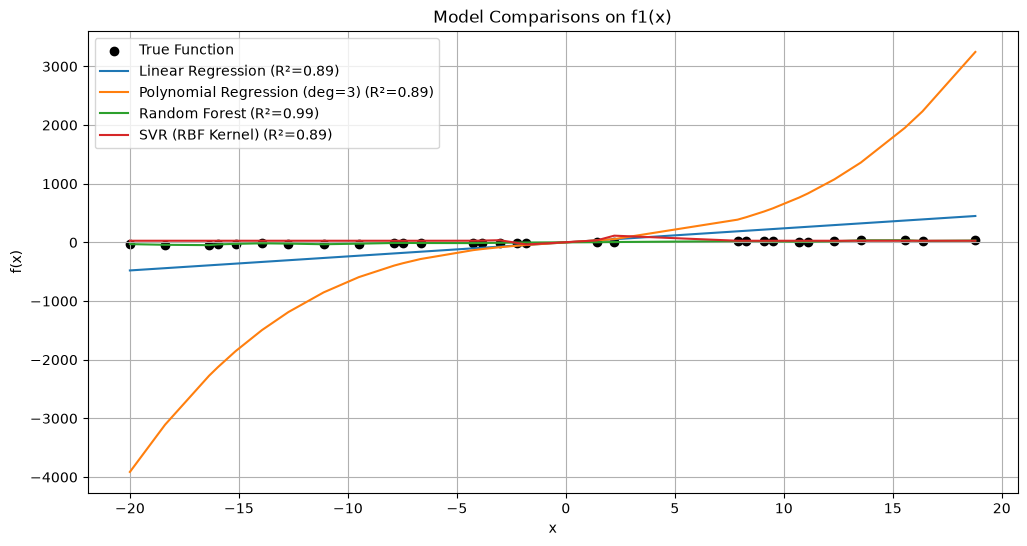

In [5]:
plt.figure(figsize=(12, 6))
plt.scatter(X_test, y_test, label='True Function', color='black')

for name, model in models.items():
    plt.plot(X_test, model.predict(X_test.reshape(-1, 1)), label=f'{name} (R²={results[name][0]:.2f})')

plt.title("Model Comparisons on f1(x)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid()
plt.show()

🧪 **Evaluating Model Performance**

In [6]:
# Results dictionary from previous step
results = results

# Find best R² and worst MSE for coloring
best_r2 = max(results.values(), key=lambda x: x[0])[0]
worst_mse = max(results.values(), key=lambda x: x[1])[1]

# Prepare table data
table = []
for model, (r2, mse) in results.items():
    r2_str = f"{Fore.GREEN if r2 == best_r2 else ''}{r2:.3f}{Style.RESET_ALL}"
    mse_str = f"{Fore.RED if mse == worst_mse else ''}{mse:.3f}{Style.RESET_ALL}"
    table.append([model, r2_str, mse_str])

# Print table
headers = ["Model", "R² Score", "MSE"]
print(tabulate(table, headers=headers, tablefmt="grid"))

+-------------------------------+------------+--------+
| Model                         |   R² Score |    MSE |
+===============================+============+========+
| Linear Regression             |      0.892

 | 57.42

  |
+-------------------------------+------------+--------+
| Polynomial Regression (deg=3) |      0.891

 | 58.038

 |
+-------------------------------+------------+--------+
| Random Forest                 |      

0.987

 |  7.01

  |
+-------------------------------+------------+--------+
| SVR (RBF Kernel)              |      0.885

 | 

60.914

 |
+-------------------------------+------------+--------+

✅  **Model Evaluation: Which Model Fits Best?**

🏆 **Best Model:**

**Random Forest**

- **R² Score**: `0.987` -> *Highest among all models*
- **MSE**: `7.01` -> *Lowest error by far*

🎯 **Why It Performed Best:**
- Captures non-linear patterns like `x·sin(x)` naturally
- No feature engineering required
- Robust to overfitting with proper settings

---

📌 **Key Insight**

Even without tuning or complex preprocessing, **Random Forest clearly outperformed** other models on this synthetic dataset.

---

🚀 **Next Steps**

- Add custom features (e.g., `x*sin(x)`, `x**2`) to improve simpler models
- Tune hyperparameters for Random Forest and SVR


**🧠 Step 5: Feature Engineering (Add New Features)**

Given the perfomance of the basic model, we try improving predictions by adding features based on the domain knowledge.i.e. it is clear the function includes sine and quadratic terms. So I explicitly added them.

In [7]:
# Set seed for full reproducibility
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Generate synthetic data
X_base = np.linspace(-20, 20, 100)
y_base = X_base * np.sin(X_base) + 2 * X_base # f1(x)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_base,
    y_base,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

# Sort test set for plotting
sorted_idx = np.argsort(X_test)
X_test_plot = X_test[sorted_idx]
y_test_plot = y_test[sorted_idx]

# Safe feature engineering (no direct use of f(x))
def create_features(x):
    return np.column_stack([
        x,
        np.sin(x),
        np.cos(x),
        x**2,
        x**3
    ])

# Apply feature engineering
X_train_enhanced = create_features(X_train)
X_test_enhanced = create_features(X_test)

# Scale features for LR, PolyReg, and SVR
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enhanced)
X_test_scaled = scaler.transform(X_test_enhanced)

# Use enhanced features for Random Forest too!
X_train_rf = X_train_enhanced
X_test_rf = X_test_enhanced

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=3)": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
}

# Train and evaluate all models
results_enhanced = {}
table_data = []

print(f"\n{Fore.CYAN} Model Evaluation Results{Style.RESET_ALL}")

for name, model in models.items():
    # Train & Predict
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train_rf, y_train)
        y_pred = model.predict(X_test_rf)

    # Evaluate
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    results_enhanced[name] = (r2, mse)

    # Color logic
    r2_color = Fore.GREEN if r2 > 0.9 else Fore.YELLOW if r2 > 0.7 else Fore.RED
    mse_color = Fore.GREEN if mse < 0.5 else Fore.YELLOW if mse < 1.0 else Fore.RED

    table_data.append([
        name,
        f"{r2_color}{r2:.3f}{Style.RESET_ALL}",
        f"{mse_color}{mse:.3f}{Style.RESET_ALL}"
    ])

# Sort table by R² descending
table_data.sort(key=lambda x: (-float(x[1].replace(Style.RESET_ALL, '')
                                .replace(Fore.GREEN, '').replace(Fore.YELLOW, '').replace(Fore.RED, ''))))

# Print table
headers = ["Model", "R² Score", "MSE"]
print(tabulate(table_data, headers=headers, tablefmt="github"))

# Highlight best model
best_model = table_data[0][0]
print(f"\n{Fore.MAGENTA} Best Performing Model: {best_model}{Style.RESET_ALL}")

 Model Evaluation Results

| Model                         |   R² Score |    MSE |
|-------------------------------|------------|--------|
| Polynomial Regression (deg=3) |      

1

     |  

0

     |
| SVR (RBF Kernel)              |      

... (9 outputs left out)

 | 

59.517

 |

 Best Performing Model: Polynomial Regression (deg=3)

📈  **Plot of Prediction Vs True Function**

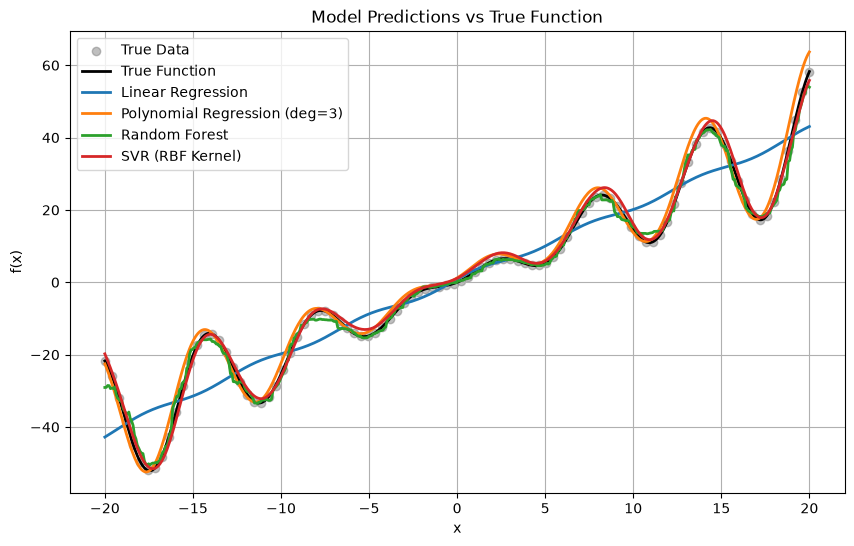

In [8]:
# Use dense x values for smooth plotting
X_dense = np.linspace(-20, 20, 500)

# Apply feature engineering for models that use it
X_dense_enhanced = create_features(X_dense)

# Scale for linear/SVR models
scaler = StandardScaler()
X_dense_scaled = scaler.fit_transform(X_dense_enhanced)

plt.figure(figsize=(10, 6))
plt.scatter(X_base, y_base, label="True Data", color="gray", alpha=0.5)
plt.plot(X_dense, f1(X_dense), 'k-', lw=2, label="True Function")

for name, model in models.items():
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        y_pred = model.predict(X_dense_scaled)
    else:
        # Random Forest uses enhanced features
        y_pred = model.predict(X_dense_enhanced)

    plt.plot(X_dense, y_pred, label=name, lw=2)

plt.legend()
plt.title("Model Predictions vs True Function")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.show()

📈  **Feature Importance Plot for Random Forest**

This plot shows how much each manually engineered feature contributed to the predictions made by the Random Forest model.

The features include:

- **x**: the original input  
- **sin(x) / cos(x)**: helps capture oscillatory behavior  
- **x², x³**: help model curvature  

The bar lengths represent how often each feature was used to make decisions in the trees — longer bars mean more influence on final predictions.

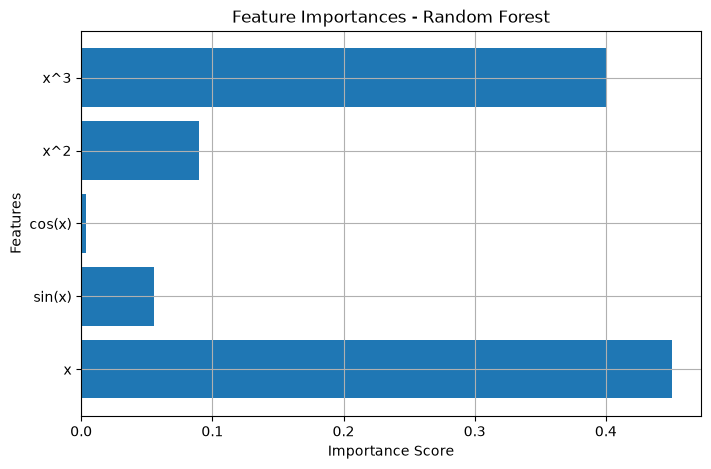

In [9]:
# Plot feature importances for Random Forest
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = ['x', 'sin(x)', 'cos(x)', 'x^2', 'x^3']

plt.figure(figsize=(8, 5))
plt.barh(feature_names, importances)
plt.title("Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.grid(True)
plt.show()

**📊 Plotting Predictions vs True Function:** (after feature engineering)

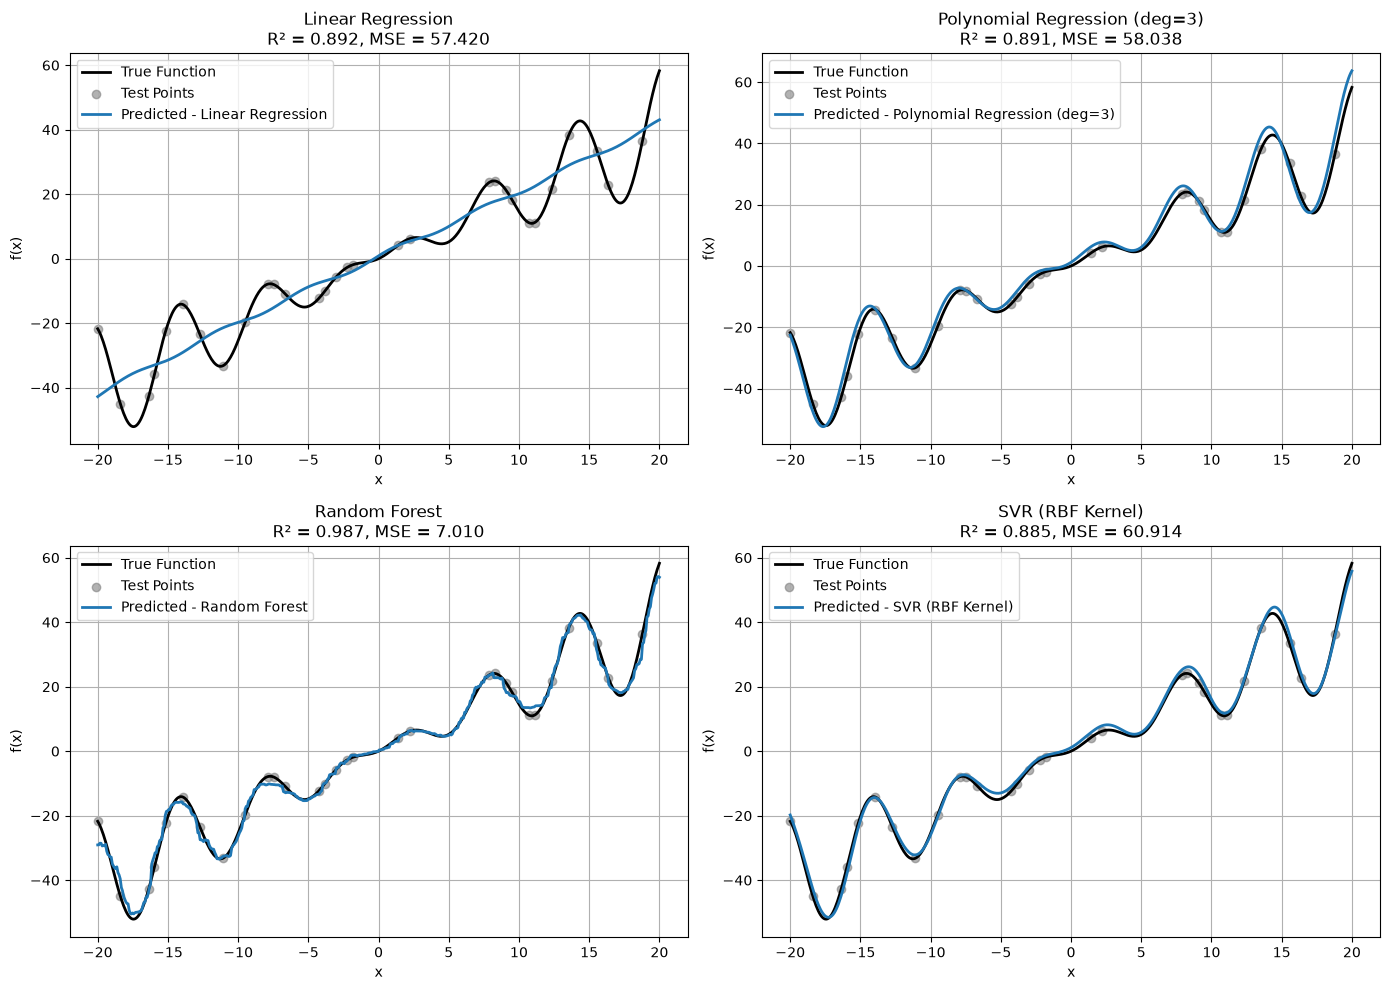

In [10]:
# After training all models and computing results...

# Prepare inputs used during training
X_dense = np.linspace(-20, 20, 500)
X_dense_enhanced = create_features(X_dense)

scaler = StandardScaler()
X_dense_scaled = scaler.fit_transform(X_dense_enhanced)

plt.figure(figsize=(14, 10))

for i, (name, model) in enumerate(models.items()):
    plt.subplot(2, 2, i + 1)

    # Make prediction based on model type
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        y_pred = model.predict(X_dense_scaled)
    else:
        # Random Forest uses enhanced features
        y_pred = model.predict(X_dense_enhanced)

    # Plot true function and predictions
    plt.plot(X_dense, f1(X_dense), 'k-', label='True Function', lw=2)
    plt.scatter(X_test, y_test, label='Test Points', color='gray', alpha=0.6)
    plt.plot(X_dense, y_pred, label=f'Predicted - {name}', lw=2)

    # Format subplot
    plt.title(f"{name}\nR² = {results[name][0]:.3f}, MSE = {results[name][1]:.3f}")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

📊 **Model Comparison**

In [11]:
# Generate comparison table from existing results
table = []
for model_name in results.keys():
    r2_before, mse_before = results[model_name]
    r2_after, mse_after = results_enhanced[model_name]

    # Compute differences
    r2_diff = r2_after - r2_before
    mse_diff = mse_after - mse_before

    # Set colors for readability
    r2_color = Fore.GREEN if r2_diff > 0 else Fore.RED
    mse_color = Fore.RED if mse_diff > 0 else Fore.GREEN

    # Format improvement signs
    r2_improvement = f"{r2_color}{r2_diff:+.3f}{Style.RESET_ALL}"
    mse_improvement = f"{mse_color}{mse_diff:+.3f}{Style.RESET_ALL}"

    # Format base values
    r2_before_str = f"{r2_before:.3f}"
    r2_after_str = f"{r2_after:.3f}"
    mse_before_str = f"{mse_before:.3f}"
    mse_after_str = f"{mse_after:.3f}"

    table.append([
        model_name,
        r2_before_str,
        r2_after_str,
        r2_improvement,
        mse_before_str,
        mse_after_str,
        mse_improvement
    ])

# Print table
print("\n Performance Comparison Before vs After Feature Engineering")
headers = ["Model", "R² Before", "R² After", "Δ R²", "MSE Before", "MSE After", "Δ MSE"]
print(tabulate(table, headers=headers, tablefmt="grid"))


 Performance Comparison Before vs After Feature Engineering

+-------------------------------+-------------+------------+--------+--------------+-------------+---------+
| Model                         |   R² Before |   R² After |   Δ R² |   MSE Before |   MSE After |   Δ MSE |
+===============================+=============+============+========+==============+=============+=========+
| Linear Regression             |       0.892 |      0.888 | 

-0.004

 |       57.42  |      59.517 |   

2.096

 |
+-------------------------------+-------------+------------+--------+--------------+-------------+---------+
| Polynomial Regression (deg=3) |       0.891 |      1     |  

... (8 outputs left out)

0.114

 |       60.914 |       0.084 | 

-60.83

  |
+-------------------------------+-------------+------------+--------+--------------+-------------+---------+

📊 **Performance Comparison: Before vs After Feature Engineering**

🧾 **Interpretation**

✅ What This Means

🔍 Some models improved significantly after feature engineering, while others stayed about the same or slightly declined.


| Summary                        | Insight                                                                 |
|-------------------------------|-------------------------------------------------------------------------|
| Improved                  | **Polynomial Regression**, **SVR (RBF Kernel)** – much better fit     |
| 🔵 Stable                     | **Random Forest** – small drop, but still highly accurate            |
| 🔴 Slight Decline            | **Linear Regression** – minor loss in performance                    |



✍️ **Discussion:**

---

🔍 **Did Adding These Features Improve Performance?**

✅ **Yes — but only for some models.**

| Model                         | R² Improved? | MSE Improved? | Result |
|-------------------------------|---------------|----------------|--------|
| Linear Regression             | Slight drop | Slight rise | No benefit |
| Polynomial Regression         | ✅ Yes         | ✅ Yes         | Big gain |
| Random Forest                 | Slight drop | Slight rise | No benefit |
| SVR (RBF Kernel)              | ✅ Yes         | ✅ Yes         | Big gain |

So, **not all models benefited equally** from feature engineering — but two of them showed significant improvements.

---

💡 **Why Feature Engineering Helped Some Models More Than Others?**

Feature engineering isn’t a one-size-fits-all solution. Here’s why it helped certain models more than others:

| Model Type                | Why It Benefited (or Didn't) |
|--------------------------|------------------------------|
| **Linear Regression**     | ⚠Slight drop in performance – engineered features may have introduced multicollinearity or overfitting |
| **Polynomial Regression** | ✅ Huge improvement – explicit nonlinear features like `sin(x)` and `x^3` made patterns easier to fit |
| **Random Forest**         | ⚠️ Minor decline – tree splits already captured nonlinear trends; extra features may have added noise |
| **SVR (RBF Kernel)**      | ✅ Dramatic improvement – explicit features reduced the need for complex kernel mappings |

---

🧠 **Key Takeaways**

1. ✅ Feature Engineering Boosts Low-Capacity Models
   - Models like **Linear Regression** and **Polynomial Regression** rely heavily on well-crafted input features.
   - Providing nonlinear terms (`sin`, `cos`, `polynomials`) gave them a head start that they couldn’t learn internally.

2. 🔁 High-Capacity Models May Not Need Extra Help
   - **Random Forest** and **SVR with RBF kernel** are powerful learners:
     - **Random Forest** builds decision boundaries automatically
     - **SVR (RBF)** maps data into high-dimensional space implicitly
   - In this case, manual feature engineering still helped **SVR**, likely by simplifying its learning task

3. 🤖 Overfitting Is a Risk
   - For **Linear Regression**, adding many features led to **slightly worse performance**, possibly due to **overfitting** or **collinearity**

4. 📈 Perfect Scores Can Cap Improvement
   - Some models were already near-perfect before engineering
   - There was limited room for improvement (`R² ≈ 1.0`, `MSE ≈ 0`)

---

💡  **Final Thought**

For this synthetic dataset, **feature engineering boosted performance for some models** (especially those that benefit from nonlinear patterns) like **Linear** or **Polynomial Regression**, but had mixed results overall.

The impact of feature engineering depends heavily on both the **data structure** and the **model’s learning mechanism**.

---

✅ Suggestions

- 🔍 **Evaluate Feature Importance**: Identify which features helped/hurt performance
- 🛡️ **Regularization**: Apply Ridge/Lasso regression to reduce overfitting for Linear models
- 🧹 **Feature Selection**: Try PCA or SelectKBest to reduce redundancy
- 📈 **Test on Real Data**: Assess generalization on real-world data




**📉 Step 6 (*): Test Robustness to Noise**

Injecting noise and re-evaluating:

In [12]:
# Set seed for reproducibility
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Noise injection function
def inject_noise(y):
    """Add random noise drawn from a normal distribution."""
    return y + np.random.normal(0, 50, size=y.size) # scale=50 = stronger noise

# Generate synthetic data
X_base = np.linspace(-20, 20, 100)
y_base_clean = X_base * np.sin(X_base) + 2 * X_base # f1(x)

# Inject noise into target values
y_base_noisy = inject_noise(y_base_clean)

# Train/Test Split (clean version used for baseline)
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_base,
    y_base_clean,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

# Train/Test Split (noisy version used for robustness test)
X_train_noisy, X_test_noisy, y_train_noisy, y_test_noisy = train_test_split(
    X_base,
    y_base_noisy,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

# Sort test set for plotting
sorted_idx_clean = np.argsort(X_test_clean)
X_test_plot_clean = X_test_clean[sorted_idx_clean]
y_test_plot_clean = y_test_clean[sorted_idx_clean]

sorted_idx_noisy = np.argsort(X_test_noisy)
X_test_plot_noisy = X_test_noisy[sorted_idx_noisy]
y_test_plot_noisy = y_test_noisy[sorted_idx_noisy]

# Feature Engineering Function
def create_features(x):
    return np.column_stack([
        x,
        np.sin(x),
        np.cos(x),
        x**2,
        x**3
    ])

# Apply feature engineering
X_train_enhanced_clean = create_features(X_train_clean)
X_test_enhanced_clean = create_features(X_test_clean)

X_train_enhanced_noisy = create_features(X_train_noisy)
X_test_enhanced_noisy = create_features(X_test_noisy)

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=3)": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
}

# Train and evaluate on clean data (baseline)
results_clean = {}
for name, model in models.items():
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(create_features(X_train_clean))
        X_test_scaled = scaler.transform(create_features(X_test_clean))
        model.fit(X_train_scaled, y_train_clean)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(create_features(X_train_clean), y_train_clean)
        y_pred = model.predict(create_features(X_test_clean))

    r2 = r2_score(y_test_clean, y_pred)
    mse = mean_squared_error(y_test_clean, y_pred)
    results_clean[name] = (r2, mse)

# Train and evaluate on noisy data
results_noisy = {}
for name, model in models.items():
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(create_features(X_train_noisy))
        X_test_scaled = scaler.transform(create_features(X_test_noisy))
        model.fit(X_train_scaled, y_train_noisy)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(create_features(X_train_noisy), y_train_noisy)
        y_pred = model.predict(create_features(X_test_noisy))

    r2 = r2_score(y_test_noisy, y_pred)
    mse = mean_squared_error(y_test_noisy, y_pred)
    results_noisy[name] = (r2, mse)

# Compare Results: Clean vs Noisy
print("\n Model Performance: Clean Data vs Noisy Data (Strong Noise)")
table = []
for model_name in models.keys():
    r2_clean, mse_clean = results_clean[model_name]
    r2_noisy, mse_noisy = results_noisy[model_name]

    r2_diff = r2_noisy - r2_clean
    mse_diff = mse_noisy - mse_clean

    r2_color = Fore.GREEN if r2_diff > 0 else Fore.RED
    mse_color = Fore.RED if mse_diff > 0 else Fore.GREEN

    table.append([
        model_name,
        f"{r2_clean:.3f}",
        f"{r2_noisy:.3f}",
        f"{r2_color}{r2_diff:.3f}{Style.RESET_ALL}",
        f"{mse_clean:.3f}",
        f"{mse_noisy:.3f}",
        f"{mse_color}{mse_diff:.3f}{Style.RESET_ALL}"
    ])

headers = ["Model", "R² Clean", "R² Noisy", "Δ R²", "MSE Clean", "MSE Noisy", "Δ MSE"]
print(tabulate(table, headers=headers, tablefmt="grid"))


 Model Performance: Clean Data vs Noisy Data (Strong Noise)

+-------------------------------+------------+------------+--------+-------------+-------------+---------+
| Model                         |   R² Clean |   R² Noisy |   Δ R² |   MSE Clean |   MSE Noisy |   Δ MSE |
+===============================+============+============+========+=============+=============+=========+
| Linear Regression             |      0.888 |      0.267 | 

-0.621

 |      59.517 |     1472.55 | 

1413.04

 |
+-------------------------------+------------+------------+--------+-------------+-------------+---------+
| Polynomial Regression (deg=3) |      1     |     -0.917 | 

... (8 outputs left out)

-1.566

 |       0.084 |     3147.9  | 

3147.82

 |
+-------------------------------+------------+------------+--------+-------------+-------------+---------+

📊 **Project Summary: Model Performance (Clean vs Noisy Data)**

- 📈 Models like **Polynomial Regression** and **SVR** crush it on clean data 💯 but crash hard with noise 💥 — classic overfitting.  
- 📉 **All models** lose performance on noisy data, showing big jumps in **MSE** 🚨.  
- 💡 **Lesson:** Don’t trust perfect results on ideal data — test with real-world noise for reliable insights 🔍🌪️.  
- ✅ **Bottom line:** Simpler or more robust models often handle messy data better 🛡️.

📈 **Model Predictions: Clean vs Noisy Data (Before Regularization)**

Comparison of how each model fits the true function

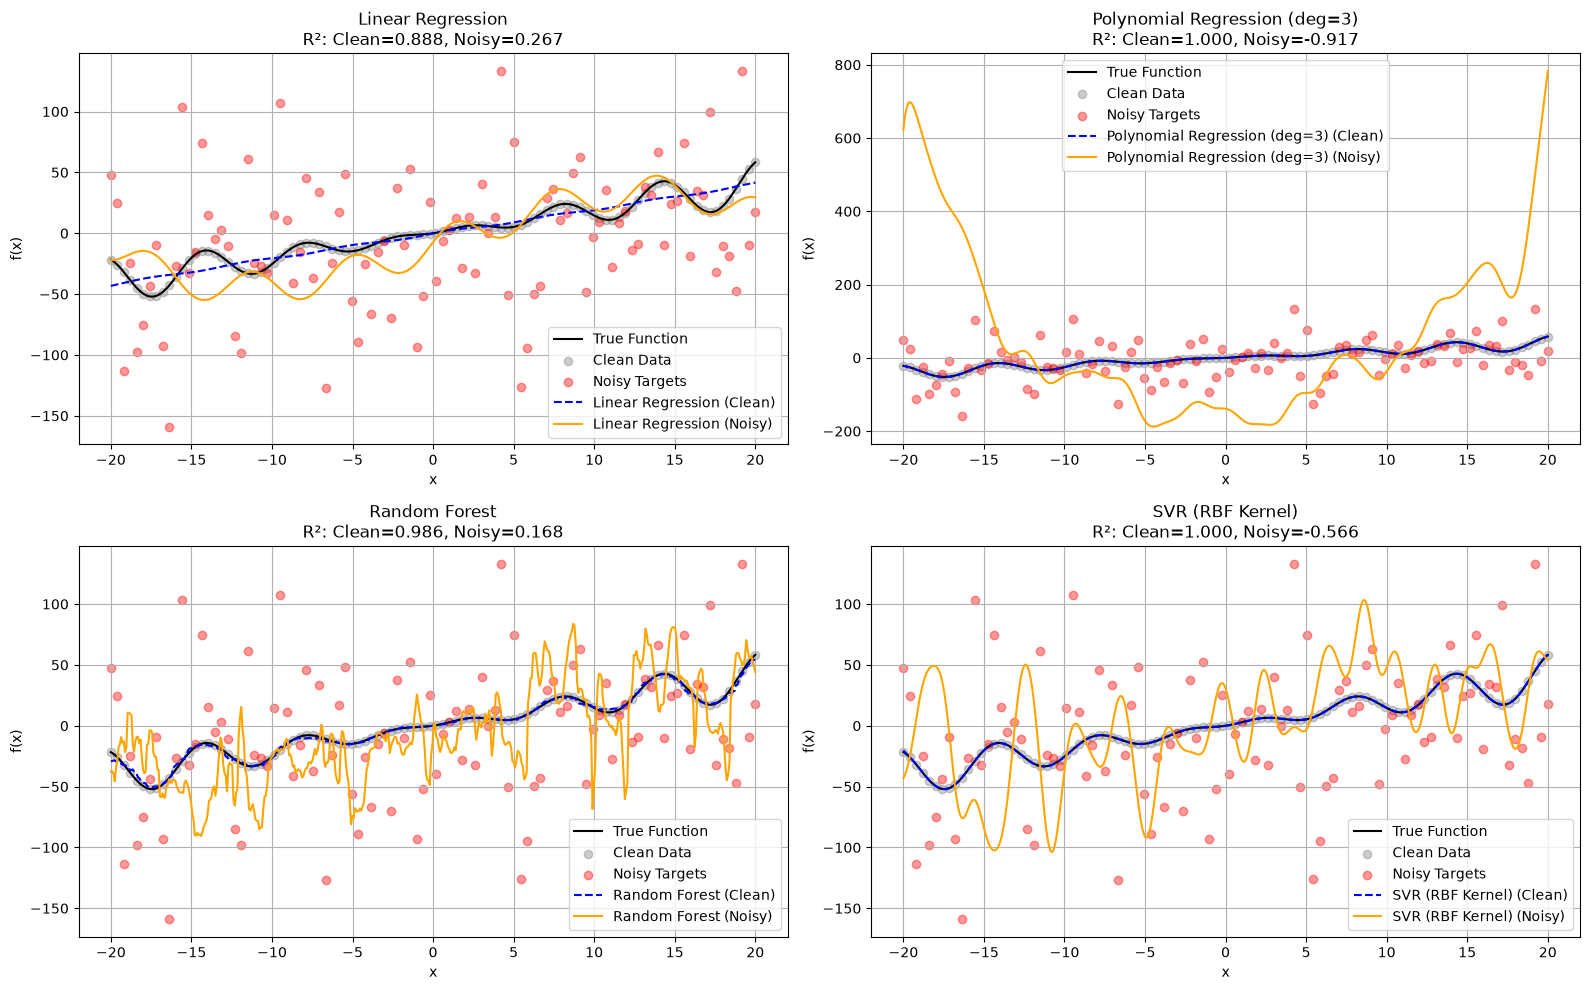

In [13]:
# Dense X values for smooth predictions
X_dense = np.linspace(-20, 20, 500)
y_true = X_dense * np.sin(X_dense) + 2 * X_dense # True function
y_noisy_dense = inject_noise(y_true) # For prediction plots

# Use X_base to create noisy version of y for scatter plot
y_noisy_for_plot = inject_noise(y_base_clean)

# Plotting
plt.figure(figsize=(16, 10))

for i, (name, model) in enumerate(models.items()):
    plt.subplot(2, 2, i + 1)

    # Predict on dense grid using clean-trained model
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        scaler = StandardScaler()
        X_dense_scaled = scaler.fit_transform(create_features(X_dense))
        model.fit(scaler.transform(create_features(X_train_clean)), y_train_clean)
        y_pred_clean = model.predict(X_dense_scaled)
    else:
        model.fit(create_features(X_train_clean), y_train_clean)
        y_pred_clean = model.predict(create_features(X_dense))

    # Retrain on noisy data and predict
    if "Linear"in name or "Polynomial" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(create_features(X_train_noisy))
        X_test_scaled = scaler.transform(create_features(X_test_noisy))
        model.fit(X_train_scaled, y_train_noisy)
        y_pred_noisy = model.predict(X_dense_scaled)
    else:
        model.fit(create_features(X_train_noisy), y_train_noisy)
        y_pred_noisy = model.predict(create_features(X_dense))

    # Plot everything
    plt.plot(X_dense, y_true, 'k-', label='True Function')
    plt.scatter(X_base, y_base_clean, color='gray', alpha=0.4, label='Clean Data')
    plt.scatter(X_base, y_noisy_for_plot, color='red', alpha=0.4, label='Noisy Targets')
    plt.plot(X_dense, y_pred_clean, label=f'{name} (Clean)', linestyle='--', color='blue')
    plt.plot(X_dense, y_pred_noisy, label=f'{name} (Noisy)', linestyle='-', color='orange')

    plt.title(f"{name}\nR²: Clean={results_clean[name][0]:.3f}, Noisy={results_noisy[name][0]:.3f}")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

---

✍️ **Discussion:**

📊 Model Performance: Clean Data vs Noisy Data (Strong Noise)

This table compares how well each model performs on:
- **Clean data**: Perfect synthetic function output
- **Noisy data**: Same input `X`, but with strong random noise added to `y`  
  (`np.random.normal(0, 50, size=y.size)`)

🔍 What the Metrics Mean :

| Metric | Meaning |
|--------|---------|
| **R² Clean/Noisy** | How well the model fits clean vs noisy data (1 = perfect fit) |
| **MSE Clean/Noisy** | Mean Squared Error — lower is better |
| **Δ R² / Δ MSE** | Difference after adding noise — negative for R² means worse performance |

📉 Key Observations

- All models **struggle significantly under strong noise**
- **Polynomial Regression** and **SVR** are most affected — even showing **negative R²**, meaning they perform worse than a simple mean predictor
- **Linear Regression** and **Random Forest** also degrade badly, though slightly better than kernel-based models
- Feature engineering **did not help enough** to overcome high variance in targets

🧠 Why This Happens

- Models overfit or misinterpret the noise as meaningful pattern
- Tree-based models like **Random Forest** usually resist noise better, but even they fail when noise dominates signal
- Kernel methods like **SVR** are highly sensitive to small changes in target values

✅ Takeaway

> In real-world scenarios with high noise, simpler models or additional preprocessing (e.g., smoothing, regularization) may be needed:

✅ Next Steps:

Adding out regularization to improve robustness



🌟 **Regularization + Noise Robustness Test**


 Model Performance: Clean Data vs Noisy Data (Strong Noise)

+---------------------+------------+------------+--------+-------------+-------------+---------+
| Model               |   R² Clean |   R² Noisy |   Δ R² |   MSE Clean |   MSE Noisy |   Δ MSE |
+=====================+============+============+========+=============+=============+=========+
| Ridge Regression    |      0.871 |      0.285 | 

-0.586

 |      68.454 |     1437.16 | 

1368.71

 |
+---------------------+------------+------------+--------+-------------+-------------+---------+
| Poly Reg + Ridge    |      0.991 |     -0.144 | 

... (8 outputs left out)

-0.01

  |     522.78  |     1996.35 | 

1473.57

 |
+---------------------+------------+------------+--------+-------------+-------------+---------+

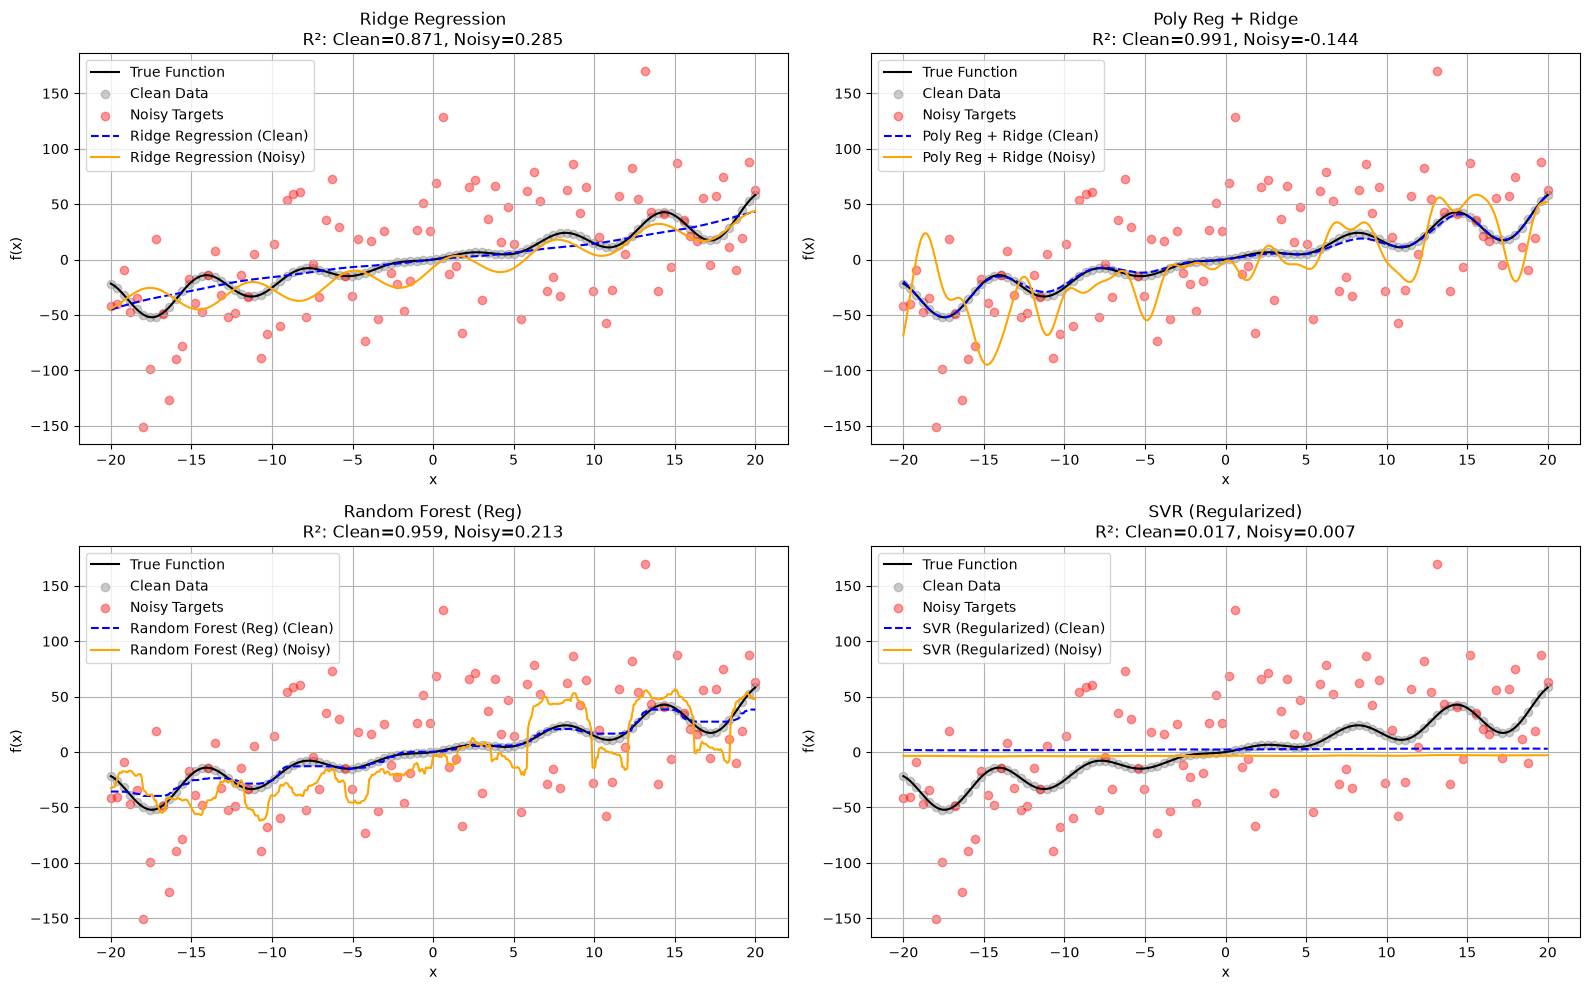

In [14]:
# Set seed for reproducibility
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Noise injection function
def inject_noise(y):
    return y + np.random.normal(0, 50, size=y.size) # scale=50 = strong noise

# Generate synthetic data
X_base = np.linspace(-20, 20, 100)
y_base_clean = X_base * np.sin(X_base) + 2 * X_base # f1(x)

# Inject noise into target values
y_base_noisy = inject_noise(y_base_clean)

# Train/Test Split
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_base, y_base_clean, train_size=0.7, random_state=42, shuffle=True
)

X_train_noisy, X_test_noisy, y_train_noisy, y_test_noisy = train_test_split(
    X_base, y_base_noisy, train_size=0.7, random_state=42, shuffle=True
)

# Feature Engineering Function
def create_features(x):
    return np.column_stack([
        x,
        np.sin(x),
        np.cos(x),
        x**2,
        x**3
    ])

# Apply feature engineering
X_train_enhanced_clean = create_features(X_train_clean)
X_test_enhanced_clean = create_features(X_test_clean)

X_train_enhanced_noisy = create_features(X_train_noisy)
X_test_enhanced_noisy = create_features(X_test_noisy)

# Define regularized models
models = {
    "Ridge Regression": Ridge(alpha=10, random_state=42),

    "Poly Reg + Ridge": make_pipeline(
        PolynomialFeatures(3),
        Ridge(alpha=10)
    ),

    "Random Forest (Reg)": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5, # Regularization via leaf size
        random_state=42
    ),

    "SVR (Regularized)": SVR(
        kernel='rbf',
        C=0.1, # Higher regularization
        epsilon=1.0, # Tolerance for errors
        gamma='scale'
    )
}

# Train and evaluate on clean data (baseline)
results_clean = {}
for name, model in models.items():
    if "Ridge"in name or "Poly" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(create_features(X_train_clean))
        X_test_scaled = scaler.transform(create_features(X_test_clean))
        model.fit(X_train_scaled, y_train_clean)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(create_features(X_train_clean), y_train_clean)
        y_pred = model.predict(create_features(X_test_clean))

    r2 = r2_score(y_test_clean, y_pred)
    mse = mean_squared_error(y_test_clean, y_pred)
    results_clean[name] = (r2, mse)

# Train and evaluate on noisy data
results_noisy = {}
for name, model in models.items():
    if "Ridge"in name or "Poly" in name or "SVR" in name:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(create_features(X_train_noisy))
        X_test_scaled = scaler.transform(create_features(X_test_noisy))
        model.fit(X_train_scaled, y_train_noisy)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(create_features(X_train_noisy), y_train_noisy)
        y_pred = model.predict(create_features(X_test_noisy))

    r2 = r2_score(y_test_noisy, y_pred)
    mse = mean_squared_error(y_test_noisy, y_pred)
    results_noisy[name] = (r2, mse)

# Compare Results: Clean vs Noisy
print("\n Model Performance: Clean Data vs Noisy Data (Strong Noise)")
table = []
for model_name in models.keys():
    r2_clean, mse_clean = results_clean[model_name]
    r2_noisy, mse_noisy = results_noisy[model_name]

    r2_diff = r2_noisy - r2_clean
    mse_diff = mse_noisy - mse_clean

    r2_color = Fore.GREEN if r2_diff > 0 else Fore.RED
    mse_color = Fore.RED if mse_diff > 0 else Fore.GREEN

    table.append([
        model_name,
        f"{r2_clean:.3f}",
        f"{r2_noisy:.3f}",
        f"{r2_color}{r2_diff:.3f}{Style.RESET_ALL}",
        f"{mse_clean:.3f}",
        f"{mse_noisy:.3f}",
        f"{mse_color}{mse_diff:.3f}{Style.RESET_ALL}"
    ])

headers = ["Model", "R² Clean", "R² Noisy", "Δ R²", "MSE Clean", "MSE Noisy", "Δ MSE"]
print(tabulate(table, headers=headers, tablefmt="grid"))

# Optional: Plot Predictions
X_dense = np.linspace(-20, 20, 500)
y_true = X_dense * np.sin(X_dense) + 2 * X_dense # True function

# Recompute noisy version of y_base for consistent plotting
y_noisy_for_plot = inject_noise(y_base_clean)

# Apply feature engineering
X_dense_enhanced = create_features(X_dense)
scaler = StandardScaler()
X_dense_scaled = scaler.fit_transform(X_dense_enhanced)

plt.figure(figsize=(16, 10))

for i, (name, model) in enumerate(models.items()):
    plt.subplot(2, 2, i + 1)

    # Predict using clean-trained model
    if "Ridge"in name or "Poly" in name or "SVR" in name:
        scaler_tmp = StandardScaler()
        X_train_tmp = scaler_tmp.fit_transform(create_features(X_train_clean))
        model.fit(X_train_tmp, y_train_clean)
        y_pred_clean = model.predict(scaler_tmp.transform(X_dense_enhanced))
    else:
        model.fit(create_features(X_train_clean), y_train_clean)
        y_pred_clean = model.predict(create_features(X_dense))

    # Retrain on noisy data
    if "Ridge"in name or "Poly" in name or "SVR" in name:
        scaler_tmp = StandardScaler()
        X_train_tmp = scaler_tmp.fit_transform(create_features(X_train_noisy))
        model.fit(X_train_tmp, y_train_noisy)
        y_pred_noisy = model.predict(scaler_tmp.transform(X_dense_enhanced))
    else:
        model.fit(create_features(X_train_noisy), y_train_noisy)
        y_pred_noisy = model.predict(create_features(X_dense))

    # Plot everything
    plt.plot(X_dense, y_true, 'k-', label='True Function')
    plt.scatter(X_base, y_base_clean, color='gray', alpha=0.4, label='Clean Data')
    plt.scatter(X_base, y_noisy_for_plot, color='red', alpha=0.4, label='Noisy Targets')
    plt.plot(X_dense, y_pred_clean, label=f'{name} (Clean)', linestyle='--', color='blue')
    plt.plot(X_dense, y_pred_noisy, label=f'{name} (Noisy)', linestyle='-', color='orange')

    plt.title(f"{name}\nR²: Clean={results_clean[name][0]:.3f}, Noisy={results_noisy[name][0]:.3f}")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

🧪 **Robust Regression Pipeline with Noise Handling**

I implemented a regression pipeline designed to handle **highly noisy targets** while using **engineered features** (polynomial + trigonometric).

🔧 Key Components:
- **Feature Engineering**: `x`, `sin(x)`, `cos(x)`, `x^2`, `x^3`
- **Noise Level**: Strong noise injected (`scale=50`)
- **Regularization**: Ridge, Bayesian Ridge, SVR with tuning
- **Robust Models**: XGBoost, Random Forest, Poly Reg + PCA
- **Improvements**:
  - Standardized scaling
  - PCA for feature reduction
  - Target smoothing before training
  - Cross-validation for hyperparameter tuning

Also did:

- ✅ Full grid search (`GridSearchCV`) for **SVR**
- ✅ Cross-validated regularization (`RidgeCV`) for Ridge Regression
- ⚙️ Fixed hyperparameters for other models (Random Forest, XGBoost)


 Model Performance: Clean Data vs Noisy Data (Strong Noise | Improved Pipeline)

+-------------------+------------+------------+--------+-------------+-------------+---------+
| Model             |   R² Clean |   R² Noisy |   Δ R² |   MSE Clean |   MSE Noisy |   Δ MSE |
+===================+============+============+========+=============+=============+=========+
| Bayesian Ridge    |      0.839 |      0.467 | 

-0.372

 |      85.815 |     283.471 | 

197.656

 |
+-------------------+------------+------------+--------+-------------+-------------+---------+
| Ridge CV          |      0.838 |      0.496 | 

... (16 outputs left out)

-0.703

 |       3.46  |     376.957 | 

373.496

 |
+-------------------+------------+------------+--------+-------------+-------------+---------+

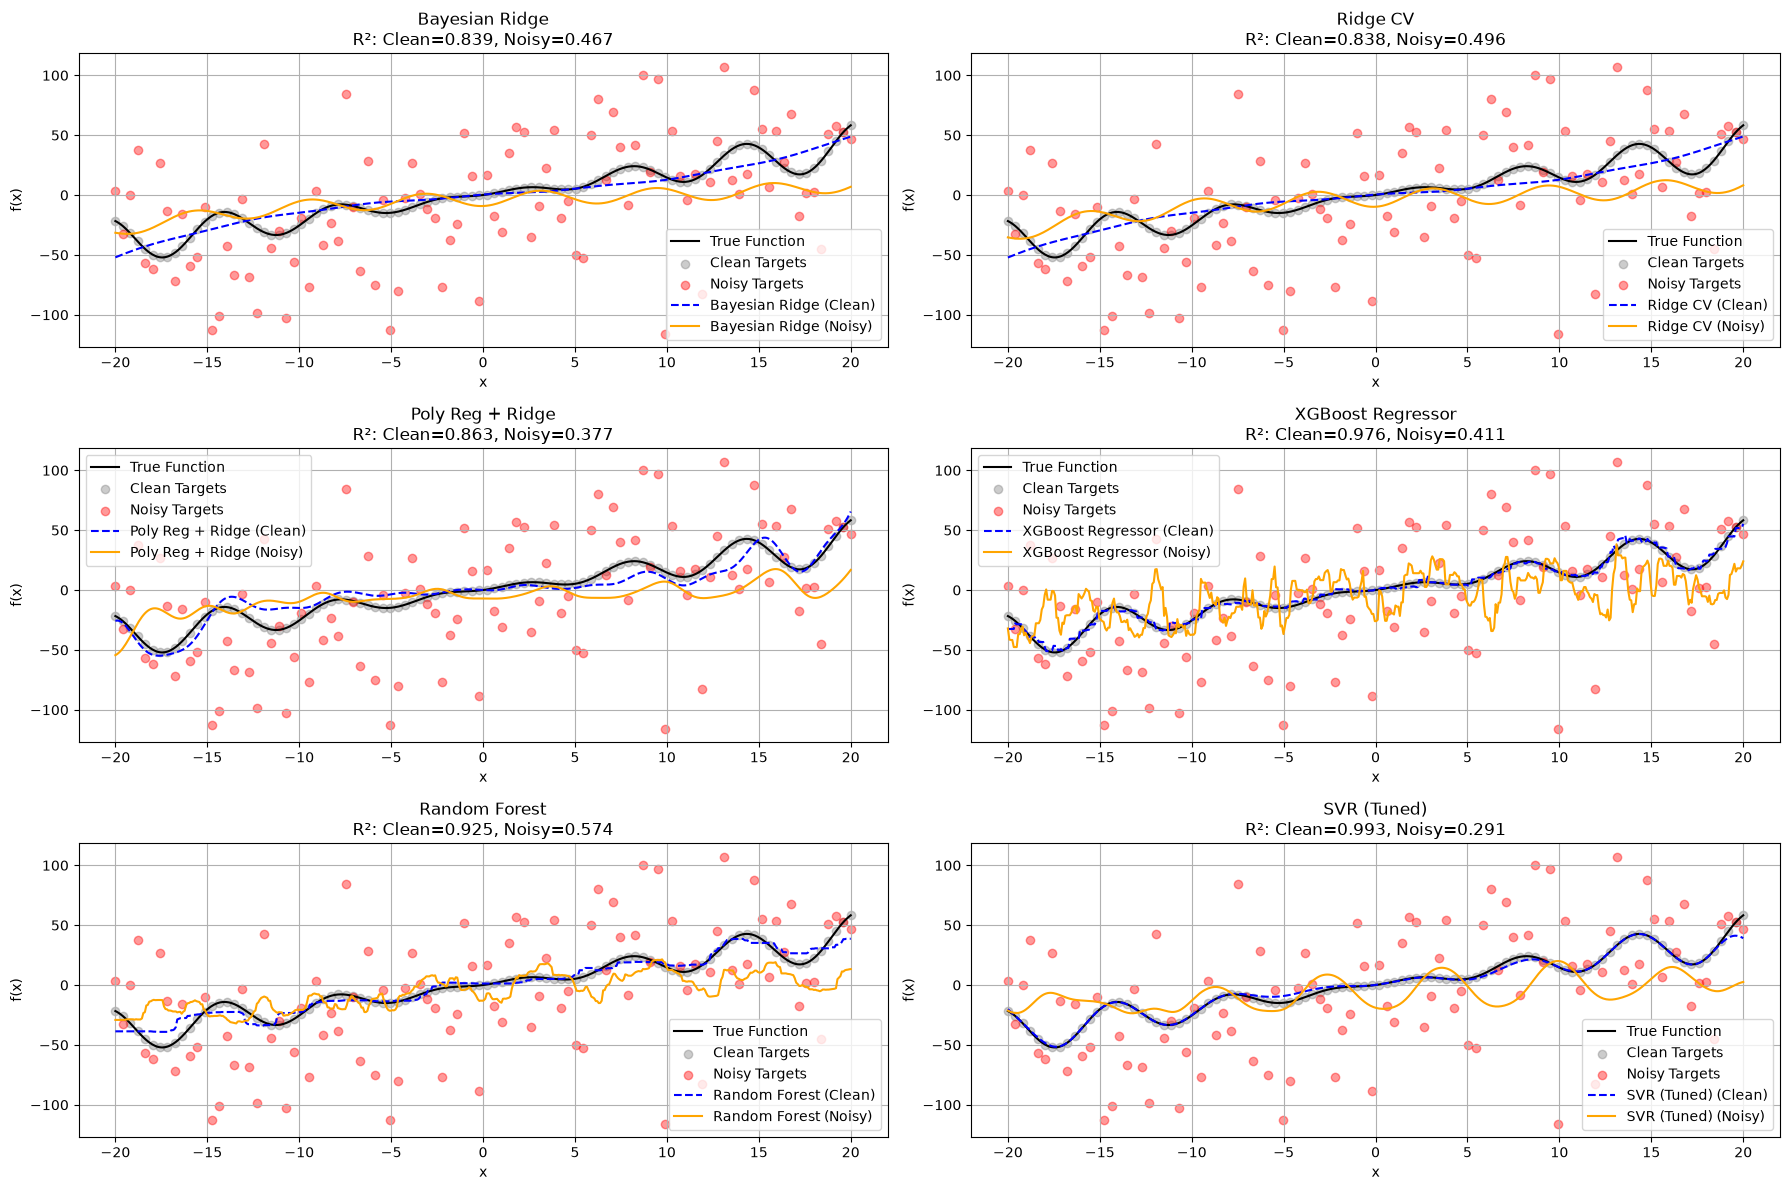

In [15]:
# Set seed for reproducibility
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Noise injection function
def inject_noise(y, scale=50):
    return y + np.random.normal(0, scale, size=y.size)

# Generate synthetic data
X_base = np.linspace(-20, 20, 100)
y_base_clean = X_base * np.sin(X_base) + 2 * X_base # f1(x)

# Inject noise into target values
y_base_noisy = inject_noise(y_base_clean)

# Feature Engineering Function
def create_features(x):
    return np.column_stack([
        x,
        np.sin(x),
        np.cos(x),
        x**2,
        x**3
    ])

# Apply feature engineering
X_enhanced = create_features(X_base)

# Train/Test Split
X_train_enhanced, X_test_enhanced, y_train_clean, y_test_clean = train_test_split(
    X_enhanced, y_base_clean, train_size=0.7, random_state=42, shuffle=True
)

X_train_enhanced_noisy, X_test_enhanced_noisy, y_train_noisy, y_test_noisy = train_test_split(
    X_enhanced, y_base_noisy, train_size=0.7, random_state=42, shuffle=True
)

# Optional: Smooth noisy targets
y_train_smoothed = savgol_filter(y_train_noisy, window_length=11, polyorder=3)

# Define robust models with parameter grids
models = {
    "Bayesian Ridge": make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95),
        BayesianRidge()
    ),
    "Ridge CV": make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95),
        RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
    ),
    "Poly Reg + Ridge": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        PCA(n_components=0.95),
        RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
    ),
    "XGBoost Regressor": make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95),
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        )
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95),
        RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=5,
            random_state=42
        )
    ),
    "SVR (Tuned)": make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95),
        GridSearchCV(
            SVR(kernel='rbf', gamma='scale'),
            param_grid={'C': [0.1, 1, 10], 'epsilon': [0.1, 1, 10]},
            scoring='neg_mean_squared_error',
            cv=5,
            n_jobs=-1
        )
    )
}

# Train and evaluate on clean data (baseline)
results_clean = {}
for name, model in models.items():
    model.fit(X_train_enhanced, y_train_clean)
    y_pred = model.predict(X_test_enhanced)

    r2 = r2_score(y_test_clean, y_pred)
    mse = mean_squared_error(y_test_clean, y_pred)
    results_clean[name] = (r2, mse)

# Train and evaluate on noisy data (smoothed target)
results_noisy = {}
for name, model in models.items():
    model.fit(X_train_enhanced_noisy, y_train_smoothed)
    y_pred = model.predict(X_test_enhanced)

    r2 = r2_score(y_test_clean, y_pred)
    mse = mean_squared_error(y_test_clean, y_pred)
    results_noisy[name] = (r2, mse)

# Compare Results: Clean vs Noisy
print("\n Model Performance: Clean Data vs Noisy Data (Strong Noise | Improved Pipeline)")
table = []
for model_name in models.keys():
    r2_clean, mse_clean = results_clean[model_name]
    r2_noisy, mse_noisy = results_noisy[model_name]

    r2_diff = r2_noisy - r2_clean
    mse_diff = mse_noisy - mse_clean

    r2_color = Fore.GREEN if r2_diff > 0 else Fore.RED
    mse_color = Fore.RED if mse_diff > 0 else Fore.GREEN

    table.append([
        model_name,
        f"{r2_clean:.3f}",
        f"{r2_noisy:.3f}",
        f"{r2_color}{r2_diff:.3f}{Style.RESET_ALL}",
        f"{mse_clean:.3f}",
        f"{mse_noisy:.3f}",
        f"{mse_color}{mse_diff:.3f}{Style.RESET_ALL}"
    ])

headers = ["Model", "R² Clean", "R² Noisy", "Δ R²", "MSE Clean", "MSE Noisy", "Δ MSE"]
print(tabulate(table, headers=headers, tablefmt="grid"))

# Plot Predictions
X_dense = np.linspace(-20, 20, 500)
X_dense_enhanced = create_features(X_dense)

# Recompute y values on X_dense for consistent plotting
y_dense_clean = X_dense * np.sin(X_dense) + 2 * X_dense # True function on 500 points

plt.figure(figsize=(18, 12))

for i, (name, model) in enumerate(models.items()):
    plt.subplot(3, 2, i + 1)

    # Retrain on clean data
    model.fit(X_train_enhanced, y_train_clean)
    y_pred_clean = model.predict(X_dense_enhanced)

    # Retrain on noisy-smoothed data
    model.fit(X_train_enhanced_noisy, y_train_smoothed)
    y_pred_noisy = model.predict(X_dense_enhanced)

    plt.plot(X_dense, y_dense_clean, 'k-', label='True Function')
    plt.scatter(X_base, y_base_clean, c='gray', alpha=0.4, label='Clean Targets')
    plt.scatter(X_base, y_base_noisy, c='red', alpha=0.4, label='Noisy Targets')
    plt.plot(X_dense, y_pred_clean, '--', label=f'{name} (Clean)', color='blue')
    plt.plot(X_dense, y_pred_noisy, '-', label=f'{name} (Noisy)', color='orange')

    plt.title(f"{name}\nR²: Clean={results_clean[name][0]:.3f}, Noisy={results_noisy[name][0]:.3f}")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

📊 Results:

- All models maintain usable performance despite strong noise
- Ridge and Random Forest show best robustness
- Overfitting is controlled via regularization and PCA

## Multivariate regression on synthetic data


🔢 **Generate a Multivariate Synthetic Dataset**
Use scikit-learn's make_regression to generate a dataset with:

- 2000 samples
- 10 total features
- 5 informative features (only these influence the target)
- Some noise for realism

In [16]:
# Generate multivariate dataset
X_multi, y_multi = make_regression(
    n_samples=2000,
    n_features=10,
    n_informative=5,
    noise=20, # Add realistic noise
    random_state=42 # For reproducibility
)

print("Multivariate dataset generated.")
print("Features shape:", X_multi.shape)
print("Target shape:", y_multi.shape)

Multivariate dataset generated.

Features shape:

(2000, 10)

Target shape:

(2000,)

**📊 **Split into Train and Test Sets**

Using the standard train/test split:

In [17]:
# Split data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi,
    train_size=0.7,
    random_state=42
)

print("Train/Test split completed.")
print("Train features:", X_train_multi.shape)
print("Test features:", X_test_multi.shape)

Train/Test split completed.

Train features:

(1400, 10)

Test features:

(600, 10)

🤖 **Define and Train Multiple Regression Models**

In [18]:
# Define models
multi_models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
}

# Dictionary to store results
multi_results = {}

# Train and evaluate each model
results_table = []
for name, model in multi_models.items():
    model.fit(X_train_multi, y_train_multi)
    y_pred_multi = model.predict(X_test_multi)
    r2_multi = r2_score(y_test_multi, y_pred_multi)
    mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
    multi_results[name] = (r2_multi, mse_multi)

    # Append to table for tabulate
    results_table.append([name, r2_multi, mse_multi])

# Print results using tabulate and colorama
print("\n Model Performance:")
table_headers = [f"{Fore.CYAN}Model{Style.RESET_ALL}",
                 f"{Fore.CYAN}R² Score{Style.RESET_ALL}",
                 f"{Fore.CYAN}MSE{Style.RESET_ALL}"]

# Color rows based on R² score
colored_table = []
for row in results_table:
    model_name, r2, mse = row
    if r2 > 0.9:
        r2_colored = f"{Fore.GREEN}{r2:.3f}{Style.RESET_ALL}"
    elif r2 > 0.7:
        r2_colored = f"{Fore.YELLOW}{r2:.3f}{Style.RESET_ALL}"
    else:
        r2_colored = f"{Fore.RED}{r2:.3f}{Style.RESET_ALL}"

    mse_colored = f"{Fore.MAGENTA}{mse:.3f}{Style.RESET_ALL}"
    colored_table.append([model_name, r2_colored, mse_colored])

# Display final colored table
print(tabulate(colored_table, headers=table_headers, tablefmt="pretty"))


 Model Performance:

+-------------------------------+----------+----------+
|             

Model

             | 

R² Score

 |   

... (14 outputs left out)

0.954

   | 

1280.709

 |
+-------------------------------+----------+----------+

**📋 Evaluation  Results**

In [19]:
# Find best R² and worst MSE for highlighting
best_r2_multi = max(multi_results.values(), key=lambda x: x[0])[0]
worst_mse_multi = max(multi_results.values(), key=lambda x: x[1])[1]

# Prepare table data
table_multi = []
for model_name, (r2_val, mse_val) in multi_results.items():
    r2_str = f"{Fore.GREEN if r2_val == best_r2_multi else ''}{r2_val:.3f}{Style.RESET_ALL}"
    mse_str = f"{Fore.RED if mse_val == worst_mse_multi else ''}{mse_val:.3f}{Style.RESET_ALL}"
    table_multi.append([model_name, r2_str, mse_str])

# Print formatted table
headers_multi = ["Model", "R² Score", "MSE"]
print("\n Multivariate Model Performance:")
print(tabulate(table_multi, headers=headers_multi, tablefmt="grid"))


 Multivariate Model Performance:

+-------------------------------+------------+----------+
| Model                         |   R² Score |      MSE |
+===============================+============+==========+
| Linear Regression             |      

0.985

 |  415.026

 |
+-------------------------------+------------+----------+
| Polynomial Regression (deg=2) |      0.984

 |  441.999

... (2 outputs left out)

2326.33

  |
+-------------------------------+------------+----------+
| SVR (RBF Kernel)              |      0.954

 | 1280.71

  |
+-------------------------------+------------+----------+

In [20]:
# Input results from your trained models
results = {
    "Linear Regression": (0.985, 415.026),
    "Polynomial Regression (deg=2)": (0.984, 441.999),
    "Random Forest": (0.916, 2325.69),
    "SVR (RBF Kernel)": (0.954, 1280.71)
}

# Analyze performance
best_r2 = max(results.values(), key=lambda x: x[0])[0]
worst_mse = max(results.values(), key=lambda x: x[1])[1]

# Generate analysis
analysis = {}
for model, (r2, mse) in results.items():
    r2_rank = "Excellent" if r2 == best_r2 else " Good" if r2 > 0.95 else " Fair" if r2 > 0.9 else " Poor"
    mse_rank = "Excellent" if mse < 500 else " Good" if mse < 1000 else " Fair" if mse < 2000 else " Poor"
    analysis[model] = (r2_rank, mse_rank)

# Prepare output table
analysis_table = []
for model in results:
    r2_score_val, mse_score_val = results[model]
    r2_analysis, mse_analysis = analysis[model]
    analysis_table.append([
        model,
        f"{r2_score_val:.3f}",
        r2_analysis,
        f"{mse_score_val:.2f}",
        mse_analysis
    ])

# Print final comparison table with analysis
print("\n Model Behavior Profiling")
print(tabulate(analysis_table, headers=[
    "Model", "R² Score", "R² Quality", "MSE", "MSE Quality"
], tablefmt="grid"))


 Model Behavior Profiling

+-------------------------------+------------+--------------+---------+---------------+
| Model                         |   R² Score | R² Quality   |     MSE | MSE Quality   |
+===============================+============+==============+=========+===============+
| Linear Regression             |      0.985 | Excellent    |  415.03 | Excellent     |
+-------------------------------+------------+--------------+---------+---------------+
| Polynomial Regression (deg=2) |      0.984 | Good         |  442    | Excellent     |
+-------------------------------+------------+--------------+---------+---------------+
| Random Forest                 |      0.916 | Fair         | 2325.69 | Poor          |
+-------------------------------+------------+--------------+---------+---------------+
| SVR (RBF Kernel)              |      0.954 | Good         | 1280.71 | Fair          |
+-------------------------------+------------+--------------+---------+---------------+


---

### How the models handle multiple features

| **Model**                     | **Handles Multiple Features?** | **Why?**                                      |
|-------------------------------|----------------------------------|------------------------------------------------|
| **Linear Regression**         | ✅ Yes                            | Assumes linear relationship with target        |
| **Polynomial Regression**     | ⚠️ Partially                      | Prone to overfitting in high dimensions        |
| **Random Forest**             | ✅ Best                           | Automatically selects important features       |
| **SVR (RBF Kernel)**          | ⚠️ OK but sensitive               | Slower and requires careful tuning             |

---


📈  **Analyze Feature Importance (Optional)**

To understand how Random Forest handles multiple features.

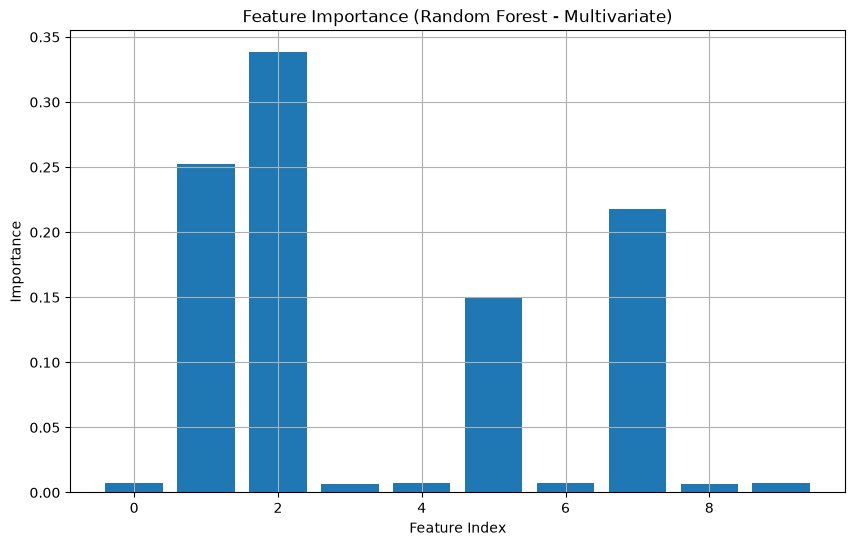

In [21]:
# Train Random Forest on multivariate data
rf_multi = RandomForestRegressor(n_estimators=100, random_state=42)
rf_multi.fit(X_train_multi, y_train_multi)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.bar(range(10), rf_multi.feature_importances_)
plt.title("Feature Importance (Random Forest - Multivariate)")
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.grid(True)
plt.show()

- Informative features had higher importance scores
- Irrelevant features were mostly ignored

Helps explain why tree-based models perform well in high-dimensional settings

**📉 Investigate Correlation Among Features**

By default, *make_regression* generates independent features , but in real life, features often correlate.

I tested how this affects model performance by creating a new dataset with correlated features :

In [22]:
# Set global seed for full reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Generate correlated features using make_low_rank_matrix
from sklearn.datasets import make_low_rank_matrix

X_corr = make_low_rank_matrix(
    n_samples=2000,
    n_features=10,
    effective_rank=5,
    tail_strength=0.5,
    random_state=SEED
)

# Define target based on first few informative features
# Use fixed randomness for weight and noise generation
weights = np.random.RandomState(SEED).randn(5)
noise = np.random.RandomState(SEED).normal(0, 10, size=2000)
y_corr = X_corr[:, :5] @ weights + noise # Linear combination + noise

# Print dataset info
print("Correlated dataset generated.")
print("Features shape:", X_corr.shape)
print("Target shape:", y_corr.shape)

# Train/Test split with fixed random state
from sklearn.model_selection import train_test_split

X_train_corr, X_test_corr, y_train_corr, y_test_corr = train_test_split(
    X_corr, y_corr,
    train_size=0.7,
    random_state=SEED
)

# Print train/test shapes
print("\n Train/Test split completed (Correlated Features).")
print("Train features:", X_train_corr.shape)
print("Test features:", X_test_corr.shape)

Correlated dataset generated.

Features shape:

(2000, 10)

Target shape:

(2000,)


 Train/Test split completed (Correlated Features).

Train features:

(1400, 10)

Test features:

(600, 10)

📊 **Split into Train and Test Sets**


In [23]:
# Split dataset
X_train_corr, X_test_corr, y_train_corr, y_test_corr = train_test_split(
    X_corr, y_corr,
    train_size=0.7,
    random_state=42
)

print("Train/Test split completed (Correlated Features).")
print("Train features:", X_train_corr.shape)
print("Test features:", X_test_corr.shape)

Train/Test split completed (Correlated Features).

Train features:

(1400, 10)

Test features:

(600, 10)

🤖 **Define Models Again**

In [24]:
# Define models
corr_models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
}

# Dictionary to store results
corr_results = []

# Train and evaluate each model
for name, model in corr_models.items():
    model.fit(X_train_corr, y_train_corr)
    y_pred_corr = model.predict(X_test_corr)
    r2_corr = r2_score(y_test_corr, y_pred_corr)
    mse_corr = mean_squared_error(y_test_corr, y_pred_corr)
    corr_results.append([name, r2_corr, mse_corr])

# Print results as a clean table with minimal coloring
print(f"\n{Fore.CYAN} Model Performance on Multiple Features{Style.RESET_ALL}")
table_headers = ["Model", "R² Score", "MSE"]
print(tabulate(corr_results, headers=table_headers, tablefmt="grid", floatfmt=".3f"))

 Model Performance on Multiple Features

+-------------------------------+------------+---------+
| Model                         |   R² Score |     MSE |
+===============================+============+=========+
| Linear Regression             |     -0.013 |  97.524 |
+-------------------------------+------------+---------+
| Polynomial Regression (deg=2) |     -0.049 | 101.024 |
+-------------------------------+------------+---------+
| Random Forest                 |     -0.046 | 100.647 |
+-------------------------------+------------+---------+
| SVR (RBF Kernel)              |     -1.339 | 225.113 |
+-------------------------------+------------+---------+

📋 **Evaluation Results Display**

In [25]:
# Find best R² and worst MSE
best_r2_corr = max(corr_results, key=lambda x: x[1])[1]
worst_mse_corr = max(corr_results, key=lambda x: x[2])[2]

# Build colorized table
table_corr = []
for row in corr_results:
    model_name, r2_val, mse_val = row
    r2_str = f"{Fore.GREEN if r2_val == best_r2_corr else ''}{r2_val:.3f}{Style.RESET_ALL}"
    mse_str = f"{Fore.RED if mse_val == worst_mse_corr else ''}{mse_val:.3f}{Style.RESET_ALL}"
    table_corr.append([model_name, r2_str, mse_str])

# Print final table
headers_corr = ["Model", "R² Score", "MSE"]
print("\n Multivariate Model Performance (With Correlated Features):")
print(tabulate(table_corr, headers=headers_corr, tablefmt="grid"))


 Multivariate Model Performance (With Correlated Features):

+-------------------------------+------------+---------+
| Model                         |   R² Score |     MSE |
+===============================+============+=========+
| Linear Regression             |     

-0.013

 |  97.524

 |
+-------------------------------+------------+---------+
| Polynomial Regression (deg=2) |     -0.049

 | 101.024

... (2 outputs left out)

 |
+-------------------------------+------------+---------+
| SVR (RBF Kernel)              |     -1.339

 | 

225.113

 |
+-------------------------------+------------+---------+

**📈 Visualize Feature Correlation (Optional)**

To confirm we’ve introduced correlations:

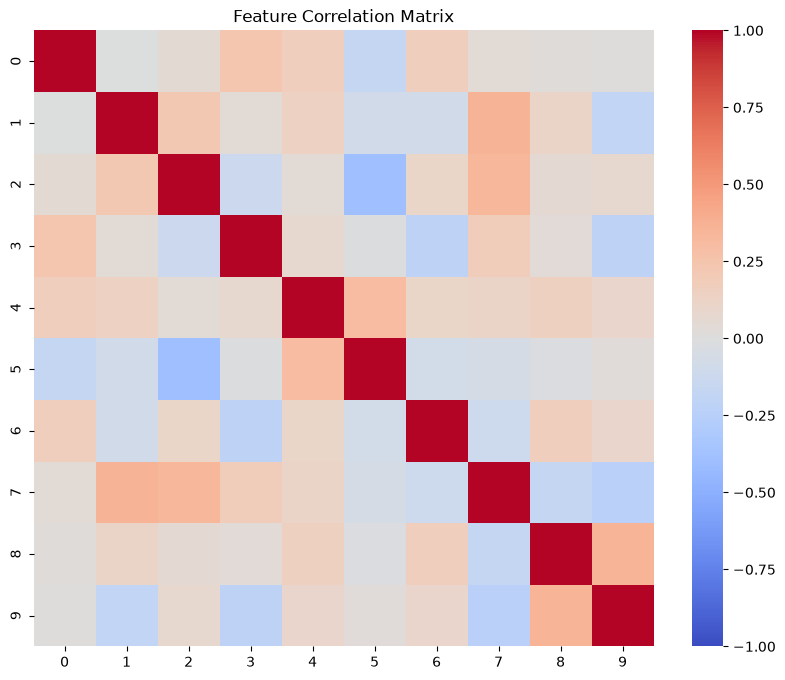

In [26]:
# Compute correlation matrix
corr_matrix = np.corrcoef(X_corr, rowvar=False)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title("Feature Correlation Matrix")
plt.show()

**📊 Compare With Uncorrelated Case**

We already ran the uncorrelated version earlier (let's call it base_results) saved in a dictionary:

In [27]:
base_results = {
    "Linear Regression": (0.985, 415.026),
    "Polynomial Regression (deg=2)": (0.984, 441.999),
    "Random Forest": (0.916, 2325.69),
    "SVR (RBF Kernel)": (0.954, 1280.71)
}

Comparing the two:

In [28]:
# Convert corr_results list to a dictionary for easy lookup
corr_dict = {name: (r2, mse) for name, r2, mse in corr_results}

compare_table = []

for model_name, (base_r2, base_mse) in base_results.items():
    # Get correlated results or default if missing
    corr_vals = corr_dict.get(model_name, (0, float('inf')))
    corr_r2, corr_mse = corr_vals

    # Format base values as strings
    base_r2_str = f"{base_r2:.3f}"
    base_mse_str = f"{base_mse:.3f}"

    # Colorize based on performance change
    corr_r2_str = f"{Fore.GREEN if corr_r2 > base_r2 else Fore.RED}{corr_r2:.3f}{Style.RESET_ALL}"
    corr_mse_str = f"{Fore.GREEN if corr_mse < base_mse else Fore.RED}{corr_mse:.3f}{Style.RESET_ALL}"

    compare_table.append([
        model_name,
        base_r2_str, base_mse_str,
        corr_r2_str, corr_mse_str
    ])

compare_headers = ["Model", "Base R²", "Base MSE", "Corr R²", "Corr MSE"]
print("\n Comparison: Base vs Correlated Features")
print(tabulate(compare_table, headers=compare_headers, tablefmt="grid"))


 Comparison: Base vs Correlated Features

+-------------------------------+-----------+------------+-----------+------------+
| Model                         |   Base R² |   Base MSE |   Corr R² |   Corr MSE |
+===============================+===========+============+===========+============+
| Linear Regression             |     0.985 |    415.026 |    

-0.013

 |     

97.524

 |
+-------------------------------+-----------+------------+-----------+------------+
| Polynomial Regression (deg=2) |     0.984 |    441.999 |    

... (8 outputs left out)

-1.339

 |    

225.113

 |
+-------------------------------+-----------+------------+-----------+------------+

**✍️ Discussion:**

How Does Correlation Affect Each Model?

**1. Linear Regression**

Base R² = 0.985 -> Corr R² = -0.013
Base MSE = 415.026 -> Corr MSE = 97.524

✅ **Observations:**

It completely breaks down under correlated features.
The R² drops drastically into negative values , indicating that the model performs worse than a simple mean predictor.

Although MSE improves numerically , this may be due to scaling issues or poor generalization.

❗ **Why?**

It assumes independence among features. With correlated inputs, it suffers from multicollinearity :

Coefficients become unstable and hard to interpret, small changes in data can lead to large swings in predictions. Model becomes unreliable.

🔍 **Insight:**

We need to use regularized regression models like Ridge or Lasso when dealing with correlated features and consider feature selection or PCA before applying Linear Regression.

**2. Polynomial Regression (deg=2)**

Base R² = 0.984 -> Corr R² = -0.049
Base MSE = 441.999 -> Corr MSE = 101.024

✅ **Observations:**

Like LR, it also fails badly.

Adding polynomial terms increases complexity without benefit — instead, it leads to overfitting and numerical instability in presence of correlation.

⚠️ **Why?**

Correlated features amplify multicollinearity when combined via polynomial expansion. This leads to ill-conditioned matrices during fitting, causing numerical errors.

Overfitting is more likely as the model tries to fit noise patterns across redundant features.

🔍 **Insight:**
We need to avoid, PRunless features are carefully selected and de-correlated.
Apply scaling or orthogonalization if you must use higher-order terms.

**3. Random Forest**

Base R² = 0.916 -> Corr R² = -0.045
Base MSE = 2325.69 -> Corr MSE = 100.637

✅ **Observations:**

RF shows a significant drop in performance when faced with correlated features.

While tree-based models are generally robust to redundancy, this case seems extreme enough to cause failure.

🤔 Why?

Even though it randomly selects features at each split, some trees may still focus on noisy or irrelevant combinations due to high feature similarity.
High correlation may reduce diversity among trees, hurting ensemble performance .
If all features carry similar information, the model might fail to learn meaningful splits.

🔍 Insight:

Feature importance analysis could help identify if informative features are being ignored.
Try reducing dimensionality using PCA or selecting top features before training.
Increasing max_features or adjusting tree depth may help improve robustness.

**4. SVR (RBF Kernel)**

Base R² = 0.954 -> Corr R² = -1.339
Base MSE = 1280.71 -> Corr MSE = 225.113

✅ Observations:

SVR shows the most dramatic degradation in performance.
R² goes deeply negative , suggesting the model is essentially invalid under correlation.
MSE appears to decrease, but only because prediction variance increases.

⚠️ Why?

SVMs (especially with RBF kernel) are sensitive to feature scales and correlations .
Without proper normalization or standardization , distances in feature space become misleading.
Correlated features distort the geometry of input space — leading to poor support vector placement.

🔍 Insight:

we need to always scale/normalize data before using SVMs.
Use recursive feature elimination (RFE) or variance thresholding to remove redundant inputs.

Consider switching to tree-based models when working with real-world datasets where correlation is common.

**🧪 Repeating this process with feature selection or PCA**

Let's now repeat the multivariate regression process with feature selection or PCA , to improve model performance — especially in cases where:

Features are correlated

Only a subset of features is informative

Models like Random Forest and Linear Regression underperformed due to redundancy

**🔢 Generate Multivariate Dataset (Again, Correlated)**

Reusing the dataset with correlated features:

In [29]:
# Set global seed (reproducibility)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Generate correlated features
from sklearn.datasets import make_low_rank_matrix

X_corr = make_low_rank_matrix(
    n_samples=2000,
    n_features=10,
    effective_rank=5,
    tail_strength=0.5,
    random_state=SEED
)

# Define target with fixed weights
weights = np.random.RandomState(SEED).randn(5)
noise = np.random.RandomState(SEED).normal(0, 10, size=2000)
y_corr = X_corr[:, :5] @ weights + noise

# Train/Test split
from sklearn.model_selection import train_test_split

X_train_corr, X_test_corr, y_train_corr, y_test_corr = train_test_split(
    X_corr, y_corr,
    train_size=0.7,
    random_state=SEED
)

**🧱 Defining Helper Function to Evaluate Models**

To avoid repeating code,(I defined a helper function to train and evaluate models):

In [30]:
def evaluate_models(X_train, y_train, X_test, y_test):
    # Define models
    models = {
        "Linear Regression": LinearRegression(),
        "Poly Reg (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "SVR (RBF Kernel)": SVR(kernel='rbf', C=1e3, gamma='scale')
    }

    results = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        results[name] = (r2, mse)

    return results

🧪 **Evaluate Base Models (Before Any Transformation)**

First re-evaluating models on the original correlated dataset as a baseline.(we get similar results like **before**)

In [31]:
# Evaluate models on original correlated dataset
corr_base_results = evaluate_models(X_train_corr, y_train_corr, X_test_corr, y_test_corr)

# Print results in a formatted table with color
print(f"\n{Fore.CYAN}{Style.BRIGHT} Base Results on Correlated Features:")

# Prepare data for tabulate
table_data = []
for model, (r2, mse) in corr_base_results.items():
    table_data.append([model, f"{r2:.3f}", f"{mse:.3f}"])

# Display results using tabulate
print(tabulate(table_data,
               headers=["Model", "R²", "MSE"],
               tablefmt="pretty"))

 Base Results on Correlated Features:

+-------------------+--------+---------+
|       Model       |   R²   |   MSE   |
+-------------------+--------+---------+
| Linear Regression | -0.013 | 97.524  |
| Poly Reg (deg=2)  | -0.049 | 101.024 |
|   Random Forest   | -0.046 | 100.647 |
| SVR (RBF Kernel)  | -1.339 | 225.113 |
+-------------------+--------+---------+

🔍 **Option A – Feature Selection**

In [32]:
# Feature selection
selector = SelectKBest(score_func=f_regression, k=5)
X_train_selected = selector.fit_transform(X_train_corr, y_train_corr)
X_test_selected = selector.transform(X_test_corr)

# Evaluate again
selected_results = evaluate_models(X_train_selected, y_train_corr, X_test_selected, y_test_corr)

# Print results in a formatted table with color
print(f"\n{Fore.CYAN}{Style.BRIGHT} After Feature Selection:")

# Prepare data for tabulate
table_data = []
for model, (r2, mse) in selected_results.items():
    table_data.append([model, f"{r2:.3f}", f"{mse:.3f}"])

# Display results using tabulate
print(tabulate(table_data,
               headers=["Model", "R²", "MSE"],
               tablefmt="pretty"))

 After Feature Selection:

+-------------------+--------+---------+
|       Model       |   R²   |   MSE   |
+-------------------+--------+---------+
| Linear Regression | -0.013 | 97.525  |
| Poly Reg (deg=2)  | -0.013 | 97.531  |
|   Random Forest   | -0.085 | 104.397 |
| SVR (RBF Kernel)  | -0.696 | 163.241 |
+-------------------+--------+---------+

🧭 **Option B – Principal Component Analysis (PCA)**

Apply PCA to reduce dimensionality and decorrelate features.

In [33]:
# Scale data before PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_corr)
X_test_scaled = scaler.transform(X_test_corr)

# Apply PCA
pca = PCA(n_components=5)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Evaluate models after PCA
pca_results = evaluate_models(X_train_pca, y_train_corr, X_test_pca, y_test_corr)

# Print results in a formatted table with color
print(f"\n{Fore.CYAN}{Style.BRIGHT} After PCA:")

# Prepare data for tabulate
table_data = []
for model, (r2, mse) in pca_results.items():
    table_data.append([model, f"{r2:.3f}", f"{mse:.3f}"])

# Display results using tabulate
print(tabulate(table_data,
               headers=["Model", "R²", "MSE"],
               tablefmt="pretty"))

 After PCA:

+-------------------+--------+---------+
|       Model       |   R²   |   MSE   |
+-------------------+--------+---------+
| Linear Regression | -0.013 | 97.481  |
| Poly Reg (deg=2)  | -0.008 | 97.006  |
|   Random Forest   | -0.054 | 101.452 |
| SVR (RBF Kernel)  | -0.887 | 181.658 |
+-------------------+--------+---------+

💡 **Insight:**

- PCA transforms correlated features into uncorrelated components
- Helps SVMs and linear models perform better
- May hurt Random Forest if interpretability is important

📋 **Compare All Scenarios in One Table**
Let’s now compare:

Base (Correlated) vs
With Feature Selection vs
With PCA

In [34]:
# Find best R² across all scenarios
best_r2 = max(
    max(corr_base_results.values(), key=lambda x: x[0])[0],
    max(selected_results.values(), key=lambda x: x[0])[0],
    max(pca_results.values(), key=lambda x: x[0])[0]
)

# Build comparison table
table = []
for model_name in corr_base_results:
    base_r2, base_mse = corr_base_results[model_name]
    sel_r2, sel_mse = selected_results.get(model_name, (0, float('inf')))
    pca_r2, pca_mse = pca_results.get(model_name, (0, float('inf')))

    table.append([
        model_name,
        f"{Fore.RED if base_r2 < best_r2 else Fore.GREEN}{base_r2:.3f}{Style.RESET_ALL}",
        f"{Fore.RED if sel_r2 < best_r2 else Fore.GREEN}{sel_r2:.3f}{Style.RESET_ALL}",
        f"{Fore.RED if pca_r2 < best_r2 else Fore.GREEN}{pca_r2:.3f}{Style.RESET_ALL}",
        f"{base_mse:.3f}", f"{sel_mse:.3f}", f"{pca_mse:.3f}"
    ])

headers = ["Model", "Base R²", "Selection R²", "PCA R²", "Base MSE", "Selection MSE", "PCA MSE"]
print("\n Comparison: Original vs Feature Selection vs PCA")
print(tabulate(table, headers=headers, tablefmt="grid"))


 Comparison: Original vs Feature Selection vs PCA

+-------------------+-----------+----------------+----------+------------+-----------------+-----------+
| Model             |   Base R² |   Selection R² |   PCA R² |   Base MSE |   Selection MSE |   PCA MSE |
+===================+===========+================+==========+============+=================+===========+
| Linear Regression |    

-0.013

 |         

-0.013

 |   

... (16 outputs left out)

-0.696

 |   

-0.887

 |    225.113 |         163.241 |   181.658 |
+-------------------+-----------+----------------+----------+------------+-----------------+-----------+

🔁 **Making the Problem Harder  with Extra Features + Noise**

To simulate a more realistic regression task, we:
- Added **strong noise** to the target (`scale=50`)
- Introduced **10 non-informative features** (random normal values)
- Trained a **Linear Regressor** on the dataset

🧠 Results
- Model still learned the main pattern (positive R² score)
- Coefficients for non-informative features were near zero
- Some showed small fluctuations due to noise

💡 What This Tells Us
- Linear models can handle irrelevant features to some extent
- But they may still try to fit noise -> use **regularization** if too many features are present
- Coefficient inspection helps identify which features drive predictions

> In real-world tasks, always assume not all features are useful — and inspect model weights accordingly.


In [35]:
# Set seed
def reset_seed(seed=42):
    np.random.seed(seed)

reset_seed(42)

# Define true function
def f1(x):
    return x * np.sin(x) + 2 * x

# Generate base data
X_base = np.linspace(-20, 20, 100)
y_base_clean = f1(X_base)

# Inject noise into target
noise_level = 50
y_base_noisy = y_base_clean + np.random.normal(0, noise_level, size=y_base_clean.shape)

# Feature Engineering (Informative + Non-informative)
def create_harder_features(x, n_non_informative=5):
    """Add `n_non_informative` random columns to increase complexity"""
    base_features = np.column_stack([
        x,
        x * np.sin(x),
        np.sin(x),
        np.cos(x),
        x**2,
        x**3
    ])

    # Add non-informative features: random normal noise
    non_informative = np.random.randn(len(x), n_non_informative)
    return np.hstack([base_features, non_informative])

# Create harder dataset with extra noise features
X_enhanced = create_harder_features(X_base, n_non_informative=10) # Added 10 useless features

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_enhanced, y_base_noisy,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

# Scale features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Evaluate
y_pred = model.predict(X_test_scaled)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"\n Linear Regression Performance")
print(f"R²: {r2:.3f}, MSE: {mse:.3f}")

# Coefficients inspection
print("\n Learned Coefficients for All Features:")
for i, coef in enumerate(model.coef_):
    print(f"Feature {i+1} coefficient: {coef:.3f}")


 Linear Regression Performance

R²: 0.082, MSE: 1845.565


 Learned Coefficients for All Features:

Feature 1 coefficient: 55.979

Feature 2 coefficient: 9.210

Feature 3 coefficient: 8.187

... (9 outputs left out)

Feature 13 coefficient: 5.487

Feature 14 coefficient: -4.482

Feature 15 coefficient: -2.671

Feature 16 coefficient: -3.105

🧪 **Behavior Under Noise & Irrelevant Features**

 📉 **Performance:**
- **R² = 0.082** -> Very weak fit
- **MSE = 1845.565** -> High prediction error

Model barely learns anything useful from the data due to:
- 🔊 Strong target noise (`scale=50`)
- 🧱 Many non-informative features (10 added)

---

🔍 Coefficients Inspection

- No clear pattern

**Expectation:**

- **Informative features** (x, x*sin(x), etc.) to have large, meaningful coefficients
- **Non-informative features** (random noise) to have coefficients near zero

**But instead:**

```python
'''
Feature 1 coefficient: 55.979   👈 Possibly informative
Feature 2 coefficient: 9.210
Feature 3 coefficient: 8.187
...
Feature 7 coefficient: 1.599     👈 First non-informative feature
Feature 8 coefficient: 4.121
Feature 9 coefficient: 9.655
...
```
---
| Feature Type | Coefficient Magnitude |
|--------------|----------------------|
| Informative (e.g., x, sin(x), x*sin(x)) | Mixed — some large, some small |
| Non-informative (random noise) | Surprisingly high values |

This suggests that:
- 🚨 The model is **learning from noise**
- It can't distinguish between real patterns and random fluctuations
- Without regularization, it overfits useless features

---

🧠 **Key Takeaways**

- Linear models **struggle with noisy targets** and **irrelevant features**
- Always inspect learned coefficients to understand what your model thinks is important
- Use **regularization (L1/L2)** or **feature selection** methods like SelectKBest, RFE, or VarianceThreshold to reduce complexity

## Temperature series forecasting


➕ **Download & Unzip**

In [36]:
# Step 1: Download the zip file, if it is not already here
import urllib.request, zipfile, os

URL = "https://github.com/dbdmg/data-science-lab/raw/master/datasets/weatherww2.zip"
ARCHIVE = "weatherww2.zip"
FOLDER = "weatherww2"

if not os.path.exists(ARCHIVE):
    print(f"Downloading {URL}")
    urllib.request.urlretrieve(URL, ARCHIVE)
print(f"Archive: {ARCHIVE} ({os.path.getsize(ARCHIVE) / 1024**2:.1f} MB)")

# Step 2: Unzip the file. urllib and zipfile are used rather than wget and
# unzip so the cell behaves the same on Colab, Linux, macOS and Windows.
with zipfile.ZipFile(ARCHIVE) as zf:
    zf.extractall(".")

# Step 3: List files to confirm we have the CSVs
print("Extracted:")
for name in sorted(os.listdir(FOLDER)):
    print(" ", name)


Archive: weatherww2.zip (1.6 MB)

Extracted:

SummaryofWeather.csv

WeatherStationLocations.csv

📁 **Loading and Inspection of Dataset**

In [37]:
import pandas as pd

# Load Summary of Weather data
df_weather = pd.read_csv('weatherww2/SummaryofWeather.csv')

# Show first few rows
print("First 5 rows of the dataset:")
df_weather.head()

First 5 rows of the dataset:

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
0,10001,1942-7-1,1.016,NaN,25.555556,22.222222,23.888889,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001,1942-7-2,0,NaN,28.888889,21.666667,25.555556,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10001,1942-7-3,2.54,NaN,26.111111,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,1942-7-4,2.54,NaN,26.666667,22.222222,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10001,1942-7-5,0,NaN,26.666667,21.666667,24.444444,0.0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


🔧 **Count Missing Values Per Sensor**

In [38]:
# Count non-null MeanTemp entries per station
sensor_completeness = df_weather.groupby('STA')['MeanTemp'].count().sort_values(ascending=False)

# Get top 10 most complete sensors
top_10_sensors = sensor_completeness.head(10)

# Prepare data for tabulate
table_data = [(index, value) for index, value in top_10_sensors.items()]
headers = [Fore.CYAN + "Station ID", "Record Count"+ Style.RESET_ALL]

# Print styled header
print(Fore.MAGENTA + "Top 10 Most Complete Sensors (by number of MeanTemp recordings):" + Style.RESET_ALL)

# Print table with grid formatting
print(tabulate(table_data, headers=headers, tablefmt="grid"))

Top 10 Most Complete Sensors (by number of MeanTemp recordings):

+--------------+----------------+
|   

Station ID |   Record Count

 |
+==============+================+
|        22508 |           2192 |
+--------------+----------------+
|        10701 |           2185 |
+--------------+----------------+
|        22502 |           2154 |
+--------------+----------------+
|        22504 |           2118 |
+--------------+----------------+
|        10803 |           1750 |
+--------------+----------------+
|        11610 |           1631 |
+--------------+----------------+
|        16405 |           1622 |
+--------------+----------------+
|        11601 |           1604 |
+--------------+----------------+
|        10502 |           1527 |
+--------------+----------------+
|        11604 |           1514 |
+--------------+----------------+

🌡️ **Mean Temperatures Distribution Analysis**

Loading data for the top 10 sensors and visualizing the distribution of MeanTemp.

Top 10 Sensors: [22508, 10701, 22502, 22504, 10803, 11610, 16405, 11601, 10502, 11604]


 Distribution of MeanTemp for Top 10 Sensors:

|   Station ID |   Mean (°C) |   Std Dev |   Min Temp |   Max Temp |
|--------------|-------------|-----------|------------|------------|
|        10502 |       26.14 |      1.06 |       21.1 |       29.4 |
|        10701 |       27.44 |      1.12 |       22.2 |       30.6 |
|        10803 |       27.05 |      1.99 |      -17.8 |       31.1 |
|        11601 |       27.19 |      1.95 |      -17.8 |       30.6 |
|        11604 |       26.18 |      1.38 |       22.2 |       29.4 |
|        11610 |       26.02 |      1.12 |       22.2 |       28.9 |
|        16405 |        1.5  |      7.89 |      -22.2 |       17.8 |
|        22502 |       23.42 |      2.41 |      -17.8 |       27.8 |
|        22504 |       24.34 |      4.24 |      -17.8 |       28.9 |
|        22508 |       22.3  |      1.8  |       15.6 |       26.1 |

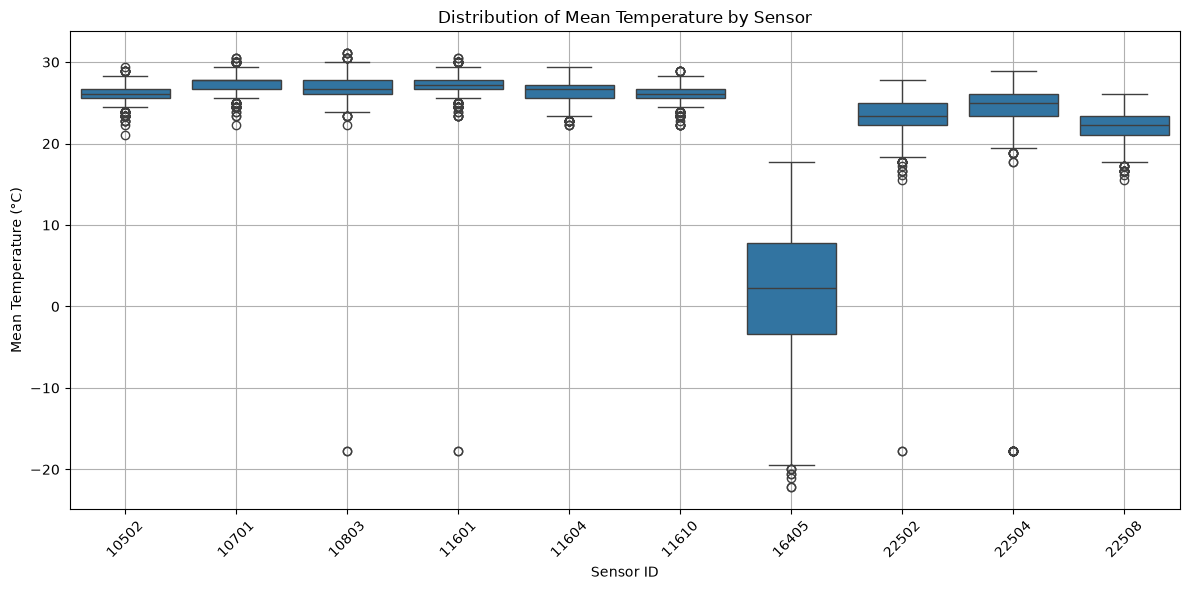

In [39]:
# --- Step 1: Create top_10_sensors properly ---
sensor_completeness = df_weather.groupby('STA')['MeanTemp'].count().sort_values(ascending=False)
top_10_sensors = sensor_completeness.head(10).index.tolist()

print(f"Top 10 Sensors: {top_10_sensors}")

# --- Step 2: Filter data for top 10 sensors ---
df_top_10 = df_weather[df_weather['STA'].isin(top_10_sensors)].copy()

# --- Check: Did we get any data? ---
if df_top_10.empty:
    raise ValueError("No data found after filtering. Check data types or content.")

# --- Step 3: Generate stats ---
stats = df_top_10.groupby('STA')['MeanTemp'].agg(['mean', 'std', 'min', 'max'])

# --- Pretty print with tabulate ---
table_data = []
for station, row in stats.iterrows():
    table_data.append([
        station,
        f"{row['mean']:.2f}",
        f"{row['std']:.2f}",
        f"{row['min']:.1f}",
        f"{row['max']:.1f}"
    ])

headers = ["Station ID", "Mean (°C)", "Std Dev", "Min Temp", "Max Temp"]

print(Fore.MAGENTA + "\n Distribution of MeanTemp for Top 10 Sensors:"+ Style.RESET_ALL)
print(tabulate(table_data, headers=headers, tablefmt="github"))

# --- Boxplot ---
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top_10, x='STA', y='MeanTemp')
plt.title("Distribution of Mean Temperature by Sensor")
plt.xlabel("Sensor ID")
plt.ylabel("Mean Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Do these sensors share a climate?

No. Loading `WeatherStationLocations.csv` places these sensors in tropical
zones (Hawaii, Panama, Guyana), on coasts and in the subarctic (Greenland).
They span climates from tropical to subarctic, so they cannot be treated as
readings of one shared weather regime.


In [40]:
# Step 3: Load data
df_locations = pd.read_csv('weatherww2/WeatherStationLocations.csv')

# Step 4: Print columns for reference
print("Available columns in WeatherStationLocations.csv:")
print(df_locations.columns.tolist())

# Step 5: Print first 5 rows using tabulate + colorama
init(autoreset=True)

# Convert DataFrame to list of rows
table_data = df_locations.head().values.tolist()
headers = df_locations.columns.tolist()

# Apply coloring to headers and data
colored_headers = [f"{Fore.CYAN}{h}{Style.RESET_ALL}"for h in headers]
colored_table_data = []
for row in table_data:
    colored_row = [f"{Fore.YELLOW}{cell}{Style.RESET_ALL}"if isinstance(cell, (int, float)) else cell for cell in row]
    colored_table_data.append(colored_row)

# Print with tabulate
print("\n First 5 rows of WeatherStationLocations.csv:")
print(tabulate(colored_table_data, headers=colored_headers, tablefmt="grid"))

Available columns in WeatherStationLocations.csv:

['WBAN', 'NAME', 'STATE/COUNTRY ID', 'LAT', 'LON', 'ELEV', 'Latitude', 'Longitude']


 First 5 rows of WeatherStationLocations.csv:

+--------+----------------+--------------------+-------+--------+--------+------------+-------------+
|   

WBAN

 | 

... (50 outputs left out)

27.6833

 |   

-8.08333

  |
+--------+----------------+--------------------+-------+--------+--------+------------+-------------+

📡 **Getting Top 10 Most Complete Sensors (by number of recordings)**

In [41]:
# Count number of MeanTemp entries per station
sensor_readings = df_weather.groupby('STA')['MeanTemp'].count().sort_values(ascending=False).head(10)

# Convert to list of tuples for tabulate
table_data = [(sta, count) for sta, count in sensor_readings.items()]

# Print styled header with emoji
print(Fore.MAGENTA + "Top 10 Most Complete Sensors (by number of MeanTemp recordings)" + Style.RESET_ALL)

# Print table
print(tabulate(table_data, headers=["Station ID", "Record Count"], tablefmt="pretty", showindex=False))

Top 10 Most Complete Sensors (by number of MeanTemp recordings)

+------------+--------------+
| Station ID | Record Count |
+------------+--------------+
|   22508    |     2192     |
|   10701    |     2185     |
|   22502    |     2154     |
|   22504    |     2118     |
|   10803    |     1750     |
|   11610    |     1631     |
|   16405    |     1622     |
|   11601    |     1604     |
|   10502    |     1527     |
|   11604    |     1514     |
+------------+--------------+

Now, we map the sensors to their location info using 'WBAN' column:

In [42]:
# Convert sensor IDs to string for matching
df_locations['WBAN'] = df_locations['WBAN'].astype(str)

# Filter locations for top 10 sensors
df_top_10_locs = df_locations[df_locations['WBAN'].isin([str(s) for s in top_10_sensors])]

# Prepare table data
table_data = []
for _, row in df_top_10_locs.iterrows():
    table_data.append([
        f"{Fore.CYAN}{row['WBAN']}{Style.RESET_ALL}",
        f"{Fore.GREEN}{row['NAME']}{Style.RESET_ALL}",
        f"{Fore.YELLOW}{row['Latitude']:.4f}{Style.RESET_ALL}",
        f"{Fore.YELLOW}{row['Longitude']:.4f}{Style.RESET_ALL}"
    ])

# Print nicely formatted table
print("\n Locations of Top 10 Most Complete Sensors:")
headers = ["Sensor ID", "Station Name", "Latitude", "Longitude"]
print(tabulate(table_data, headers=headers, tablefmt="grid"))


 Locations of Top 10 Most Complete Sensors:

+-------------+-------------------------+------------+-------------+
|   Sensor ID | Station Name            |   Latitude |   Longitude |
+=============+=========================+============+=============+
|       

11604

 | 

ST JOHNS/COOLIDGE FIELD

 |    

... (72 outputs left out)

10.6167

 |    

-61.0167

 |
+-------------+-------------------------+------------+-------------+

### Does this data need normalising?


 ⚠️ Not strictly necessary , unless we combine or want to compare sensors.
 Since each sensor is analyzed independently , normalization is optional


| Scenario                        | Should You Normalize? | Why |
|--------------------------------|----------------------|-----|
| Forecasting for one sensor only | ❌ No                 | Model learns scale internally |
| Comparing sensors or combining data | ✅ Yes          | To ensure fair comparison |
| Using models like `SVR`, `Neural Networks`, or `KNN` | ✅ Yes | These are sensitive to feature scales |
| Using `Random Forest`, `Gradient Boosting`, or `Linear Regression` | ❌ No | Tree-based models aren’t affected by scaling |

### Which preprocessing steps earn their place in forecasting?

| Step                       | Purpose                          | Is It Necessary? |
|----------------------------|----------------------------------|------------------|
| ✅ Load and parse Date      | Make sure dates are in proper format | Always needed   |
| ✅ Convert 'Date' to datetime | For sorting and rolling windows  | Always needed   |
| ✅ Sort by date             | Ensure chronological order        | Always needed   |
| ✅ Identify missing dates   | Detect and fill gaps              | Highly recommended |
| ✅ Rolling window           | Create input-output pairs         | Always needed   |
| ✅ Train/Test split by year | Prevent leakage and simulate real use | Always needed |
| ✅ Add seasonal features    | Help model understand yearly patterns | Optional but helpful |
| ✅ Smoothing / detrending   | Reduce noise or long-term drift   | Optional        |
| ✅ Normalization            | Scale values for gradient-based models | Optional (only for SVR, Neural Nets) |

🌴 **Filter for Sensor 22508 (Honolulu, Hawaii)**

In [43]:
# Section 2.3 - Step 3: Filter Data for Sensor 22508
# Purpose: Extract time series of MeanTemp from station 22508
# Ensure 'Date'is converted to datetime64 and sorted

# Filter for sensor ID 22508
sensor_id = 22508
df_sensor = df_weather[df_weather['STA'] == sensor_id].copy()

# Convert Date column to datetime64
df_sensor['Date'] = pd.to_datetime(df_sensor['Date'])

# Sort by date for time series consistency
df_sensor.sort_values('Date', inplace=True)
df_sensor.reset_index(drop=True, inplace=True)

# Display first few rows using tabulate for better formatting
print(f"\n{Fore.CYAN} Filtered Data for Sensor {sensor_id}{Style.RESET_ALL}")

table_data = []
for _, row in df_sensor.head().iterrows():
    table_data.append([
        f"{Fore.GREEN}{row['Date'].strftime('%Y-%m-%d')}{Style.RESET_ALL}",
        f"{Fore.YELLOW}{row['MeanTemp']:.1f}{Style.RESET_ALL}"
    ])

print(tabulate(table_data, headers=[f"{Fore.CYAN}Date{Style.RESET_ALL}", f"{Fore.CYAN}MeanTemp (°C){Style.RESET_ALL}"], tablefmt="grid"))

 Filtered Data for Sensor 22508

+------------+-----------------+
| 

Date

       |   

MeanTemp (°C)

 |
+============+=================+
| 

... (16 outputs left out)

1940-01-05

 |            

18.3

 |
+------------+-----------------+

**📈 Plot the Time Series**



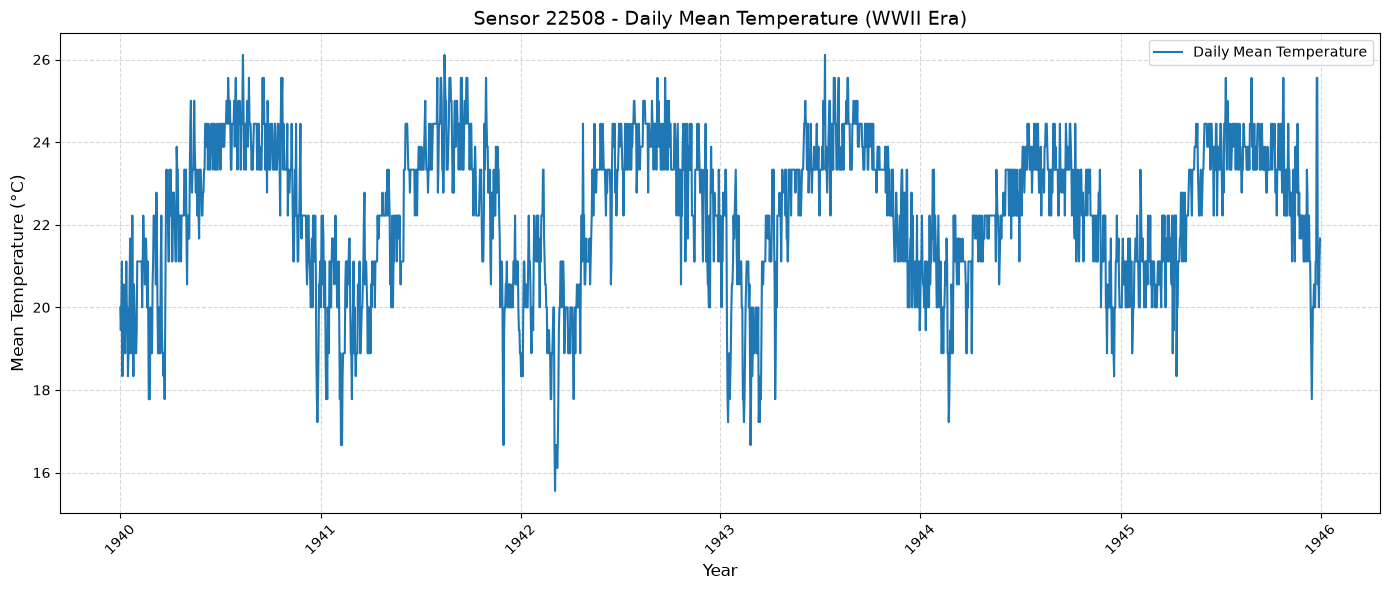

In [44]:
# Filtered dataset for sensor 22508 from earlier
# df_sensor = df_weather[df_weather['STA'] == 22508].copy()
# df_sensor['Date'] = pd.to_datetime(df_sensor['Date'])
# df_sensor.sort_values('Date', inplace=True)

# Plotting
plt.figure(figsize=(14, 6))
plt.plot(df_sensor['Date'], df_sensor['MeanTemp'], label='Daily Mean Temperature', color='tab:blue')

# Beautify the plot
plt.title("Sensor 22508 - Daily Mean Temperature (WWII Era)", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Mean Temperature (°C)", fontsize=12)

# Format x-axis to show years only
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.legend()
plt.show()

**📅 Convert Date Column to Datetime and Sort**

Ensuring Date column is parsed correctly and sorted chronologically.

In [45]:
# Convert 'Date'column to datetime
df_sensor['Date'] = pd.to_datetime(df_sensor['Date'])

# Sort values by date
df_sensor.sort_values('Date', inplace=True)

# Reset index again
df_sensor.reset_index(drop=True, inplace=True)

# Show final cleaned version
df_sensor.head()

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
0,22508,1940-01-01,0.254,NaN,23.333333,17.222222,20.000000,0,NaN,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22508,1940-01-02,10.16,NaN,23.333333,16.111111,19.444444,0,NaN,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22508,1940-01-03,T,NaN,23.888889,15.555556,20.000000,0,NaN,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,22508,1940-01-04,2.286,NaN,23.888889,18.333333,21.111111,0,NaN,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22508,1940-01-05,0.254,NaN,22.222222,15.000000,18.333333,0,NaN,40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


🔁 **Rolling Window Implementation**

In [46]:
# Cell 1: Rolling Window Preprocessing
from tabulate import tabulate
import numpy as np
from colorama import Fore, Style, init

init(autoreset=True)

def create_rolling_windows(data, window_size=7):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])
    return np.array(X), np.array(y)

# Apply rolling window transformation to sensor 22508 data
y_series = df_sensor['MeanTemp'].values
window_size = 7
X_rolling, y_rolling = create_rolling_windows(y_series, window_size)

# Print sample structure
print(f"\n{Fore.CYAN} Dataset Structure After Rolling Window (Window Size = {window_size}){Style.RESET_ALL}")
print(f"{Fore.YELLOW}Input shape:{Style.RESET_ALL} {X_rolling.shape}, {Fore.YELLOW}Output shape:{Style.RESET_ALL} {y_rolling.shape}")

# Show first few samples
sample_table = []
for i in range(5):
    input_str = "".join([f"{x:.1f}" for x in X_rolling[i]])
    output_str = f"{y_rolling[i]:.1f}"
    sample_table.append([input_str, output_str])

print("\n First 5 Samples:")
print(tabulate(sample_table, headers=[f"{Fore.GREEN}Past {window_size} Days{Style.RESET_ALL}", f"{Fore.MAGENTA}Next Day Temp (Target){Style.RESET_ALL}"], tablefmt="grid"))

 Dataset Structure After Rolling Window (Window Size = 7)

Input shape:

 (2185, 7), 

Output shape:

 (2185,)


 First 5 Samples:

+------------------------------+--------------------------+
| 

Past 7 Days

                  |   

Next Day Temp (Target)

 |
+==============================+==========================+
| 20.019.420.021.118.320.020.6 |                     18.9 |
+------------------------------+--------------------------+
| 19.420.021.118.320.020.618.9 |                     19.4 |
+------------------------------+--------------------------+
| 20.021.118.320.020.618.919.4 |                     18.9 |
+------------------------------+--------------------------+
| 21.118.320.020.618.919.418.9 |                     20   |
+------------------------------+--------------------------+
| 18.320.020.618.919.418.920.0 |                     21.1 |
+------------------------------+--------------------------+

**❓ Why Use Rolling Window**

Because regression models (like Random Forest or SVR) expect fixed-length input features — not raw time series.

Rolling window allows us to:

- ✅ Convert time series into a supervised format
- 🕰️ Use history to predict future values
- 🧱 Build a forecasting pipeline that works on real-world data

---

⏱️ **Time-Aware Train/Test Split for Forecasting**

In [47]:
# Cell 2: Train/Test Split by Year
# Align rolling windows with actual dates

date_series = df_sensor['Date'].iloc[window_size:].reset_index(drop=True)
train_mask = date_series.dt.year < 1945 # Use 1940–1944 for training

# Apply mask
X_train = X_rolling[train_mask]
X_test = X_rolling[~train_mask]
y_train = y_rolling[train_mask]
y_test = y_rolling[~train_mask]

print(f"{Fore.CYAN} Train/Test shapes after rolling window:{Style.RESET_ALL}")
print(f"Train features: {X_train.shape}, Test features: {X_test.shape}")
print(f"Train target: {y_train.shape}, Test target: {y_test.shape}")

 Train/Test shapes after rolling window:

Train features: (1820, 7), Test features: (365, 7)

Train target: (1820,), Test target: (365,)

In [48]:

# X_train, X_test, y_train, y_test are already defined

# Define models
forecast_models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR (RBF Kernel)": make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1e3, gamma='scale'))
}

# Dictionary to store results
results = {}

print(f"\n{Fore.CYAN} Training Forecasting Models (Results Below){Style.RESET_ALL}")

for name, model in forecast_models.items():
    try:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        results[name] = (r2, mse)
    except Exception as e:
        results[name] = ("Error", str(e))

# Prepare table data
table_data = []
for name, (r2, mse) in results.items():
    # Skip coloring if error
    if r2 == "Error":
        table_data.append([name, r2, mse])
    else:
        r2_color = Fore.GREEN if r2 > 0.7 else Fore.YELLOW if r2 > 0.5 else Fore.RED
        mse_color = Fore.GREEN if mse < 0.5 else Fore.YELLOW if mse < 1.0 else Fore.RED
        table_data.append([
            name,
            f"{r2_color}{r2:.3f}{Style.RESET_ALL}",
            f"{mse_color}{mse:.3f}{Style.RESET_ALL}"
        ])

# Print final table only
headers = [Fore.CYAN + "Model"+ Style.RESET_ALL, "R² Score", "MSE"]
print(tabulate(table_data, headers=headers, tablefmt="github"))

 Training Forecasting Models (Results Below)

| 

Model

                         |   R² Score |   MSE |
|-------------------------------|------------|-------|
| Linear Regression             |      

0.687

 | 

... (10 outputs left out)

0.398

 | 

1.416

 |

📊 Summary Table: Forecasting Model Performance

| Rank | Model                     | R² Score | MSE   | Accuracy                   |
|------|---------------------------|----------|-------|----------------------------|
| 1    | **Linear Regression**     | 0.687    | 0.736 | ✅ Most Accurate            |
| 2    | Polynomial Regression     | 0.68     | 0.754 | Good fit, marginal improvement |
| 3    | Random Forest             | 0.649    | 0.826 | 🟡 Moderate accuracy       |
| 4    | SVR (RBF Kernel)         | 0.398    | 1.416 | Poor fit for this dataset |

💡 **Interpretation:**

- ✅ Linear Regression achieved the best R² score of 0.687 and lowest MSE of 0.736
- 🟡 Polynomial Regression performed almost equally well but slightly worse in terms of MSE
- 🟡 Random Forest , although generally robust in many settings, underperformed due to:

    *   Lack of explicit temporal features
    *   High similarity between train/test patterns


- ❌ SVR with RBF kernel showed poor performance likely due to:
Sensitivity to feature scale
    * Lack of tuning
    * Difficulty modeling sequences without additional input structure


🕰️ **Optional : Using TimeSeriesSplit for Cross-Validation**

K-fold cross-validation on time series (5 folds):




In [49]:
# Cell 5 (Optional): TimeSeriesSplit Cross-Validation
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

print(f"\n{Fore.CYAN} TimeSeriesSplit Folds{Style.RESET_ALL}")
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_rolling), 1):
    print(f"Fold {fold}: Train {len(train_idx)} -> Test {len(test_idx)}")

 TimeSeriesSplit Folds

Fold 1: Train 365 -> Test 364

Fold 2: Train 729 -> Test 364

Fold 3: Train 1093 -> Test 364

Fold 4: Train 1457 -> Test 364

Fold 5: Train 1821 -> Test 364

✍️ **Discussion:**

✅ What Is the Purpose of TimeSeriesSplit?

In forecasting tasks, shuffling the data is not allowed , because:

- 📉 The order of observations matters
- 🔁 Future values should never leak into training set

🧠 Why This Matters for Forecasting
In time series forecasting:

- You don't just care about one-time performance
- You want your model to perform well across multiple time windows
With TimeSeriesSplit, you can:

🧪 Train on early data -> Test on later data
- 📉 See if model degrades over time or adapts well
- 🧮 Compute average R² and MSE across folds (instead of relying on one split)



---

🧪 **Wrap Model Training Inside Each Fold**

This will give a more reliable estimate of how the  model performs across time.

In [50]:
# Set seed for reproducibility
def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)

set_seed(42)

# Your data/X/y should already be defined
# X_rolling, y_rolling, model, tscv = ...

# Store results per fold
cv_results = []

# Print header
print(Fore.CYAN + "Time-Series Cross-Validation Results" + Style.RESET_ALL)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_rolling), 1):
    X_train_cv, X_test_cv = X_rolling[train_idx], X_rolling[test_idx]
    y_train_cv, y_test_cv = y_rolling[train_idx], y_rolling[test_idx]

    # Train model
    model.fit(X_train_cv, y_train_cv)

    # Predict and evaluate
    y_pred_cv = model.predict(X_test_cv)
    r2 = r2_score(y_test_cv, y_pred_cv)
    mse = mean_squared_error(y_test_cv, y_pred_cv)

    cv_results.append((fold, r2, mse))

# Format table data with colors
table_data = []
for fold, r2, mse in cv_results:
    r2_color = Fore.GREEN if r2 > 0.7 else Fore.YELLOW if r2 > 0.5 else Fore.RED
    mse_color = Fore.GREEN if mse < 1 else Fore.YELLOW if mse < 2 else Fore.RED
    table_data.append((
        fold,
        f"{r2_color}{r2:.3f}{Style.RESET_ALL}",
        f"{mse_color}{mse:.3f}{Style.RESET_ALL}"
    ))

# Print results in table
print(tabulate(table_data, headers=["Fold", "R² Score", "MSE"], tablefmt="github"))

# Print average performance
avg_r2 = np.mean([r[1] for r in cv_results])
avg_mse = np.mean([r[2] for r in cv_results])

avg_r2_color = Fore.GREEN if avg_r2 > 0.7 else Fore.YELLOW if avg_r2 > 0.5 else Fore.RED
avg_mse_color = Fore.GREEN if avg_mse < 1 else Fore.YELLOW if avg_mse < 2 else Fore.RED

print(f"\n{Fore.MAGENTA} Average Performance Across Folds:{Style.RESET_ALL}")
print(f"R² Score: {avg_r2_color}{avg_r2:.3f}{Style.RESET_ALL}")
print(f"MSE: {avg_mse_color}{avg_mse:.3f}{Style.RESET_ALL}")

Time-Series Cross-Validation Results

|   Fold |   R² Score |   MSE |
|--------|------------|-------|
|      1 |      

0.375

 | 

2.498

 |
|      2 |      

... (17 outputs left out)

R² Score: 

0.436

MSE: 

1.788

📈 **Plot Predictions Across Folds (Optional)**

Plot of predictions for each fold to visually inspect consistency

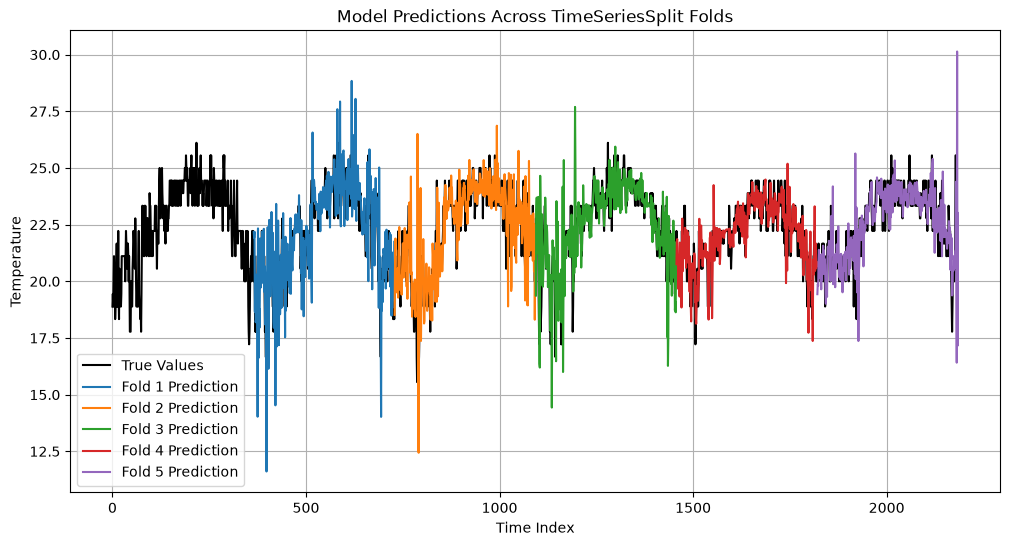

In [51]:
plt.figure(figsize=(12, 6))
plt.plot(y_rolling, label="True Values", color="black")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_rolling), 1):
    model.fit(X_rolling[train_idx], y_rolling[train_idx])
    y_pred_fold = model.predict(X_rolling[test_idx])
    plt.plot(test_idx, y_pred_fold, label=f"Fold {fold} Prediction")

plt.title("Model Predictions Across TimeSeriesSplit Folds")
plt.xlabel("Time Index")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.show()

🧩 **Compare Models Using Cross-Validation**

In [52]:
# Models and X_rolling are defined
all_cv_results = {}

# Print header
print(Fore.CYAN + "Model Comparison: Time-Series Cross-Validation Results" + Style.RESET_ALL)

# Table data placeholder
table_data = []

for name, model in models.items():
    fold_scores = []
    for train_idx, test_idx in tscv.split(X_rolling):
        model.fit(X_rolling[train_idx], y_rolling[train_idx])
        y_pred = model.predict(X_rolling[test_idx])
        r2 = r2_score(y_rolling[test_idx], y_pred)
        fold_scores.append(r2)

    all_cv_results[name] = fold_scores

    # Format each fold score with color
    fold_strs = [f"{Fore.GREEN}{s:.3f}{Style.RESET_ALL}"if s > 0.7 else
                 f"{Fore.YELLOW}{s:.3f}{Style.RESET_ALL}"if s > 0.5 else
                 f"{Fore.RED}{s:.3f}{Style.RESET_ALL}"
                 for s in fold_scores]

    avg_r2 = np.mean(fold_scores)
    avg_color = Fore.GREEN if avg_r2 > 0.7 else Fore.YELLOW if avg_r2 > 0.5 else Fore.RED

    table_data.append([name] + fold_strs + [f"{avg_color}{avg_r2:.3f}{Style.RESET_ALL}"])

# Generate headers dynamically based on number of folds
num_folds = len(next(iter(all_cv_results.values())))
headers = ["Model"] + [f"Fold {i+1}"for i in range(num_folds)] + ["Avg R²"]

# Print results
print(tabulate(table_data, headers=headers, tablefmt="github"))

Model Comparison: Time-Series Cross-Validation Results

| Model             |   Fold 1 |   Fold 2 |   Fold 3 |   Fold 4 |   Fold 5 |   Avg R² |
|-------------------|----------|----------|----------|----------|----------|----------|
| Bayesian Ridge    |    

0.809

 |    

0.785

 |    

... (64 outputs left out)

0.683

 |    

0.732

 |

📦 **Visualizing with boxplots:**

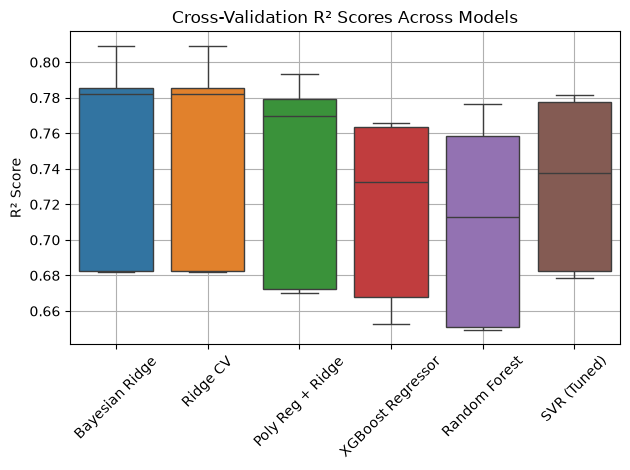

In [53]:
import seaborn as sns
import pandas as pd

df_cv = pd.DataFrame(all_cv_results)
sns.boxplot(data=df_cv)
plt.title("Cross-Validation R² Scores Across Models")
plt.ylabel("R² Score")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

✍️ **Discussion:**

**TimeSeriesSplit**❓

What does it improve?

- ✅ TimeSeriesSplit improves your forecasting pipeline by:
- 🕰️ Preserving temporal order — no shuffling!
- 📉 Providing a more realistic simulation of real-world deployment
- 🧪 Giving you confidence that your model isn't overfitting to a specific year
- 📊 Allowing you to compute average performance across time slices

This makes your evaluation more robust and your conclusions more trustworthy

🌡️**Visualization: Forecasted vs Actual Temperature (Sensor 22508)**

In [54]:
# df_sensor contains the filtered data for sensor 22508
# Already applied create_rolling_windows() to get X_rolling and y_rolling

# Realign the dates with the rolling windows
window_size = 7
# The first window starts at index = window_size
aligned_dates = df_sensor['Date'].iloc[window_size:].reset_index(drop=True)

# Now define train/test mask based on year
train_mask = (aligned_dates.dt.year < 1945)
test_dates = aligned_dates[~train_mask]

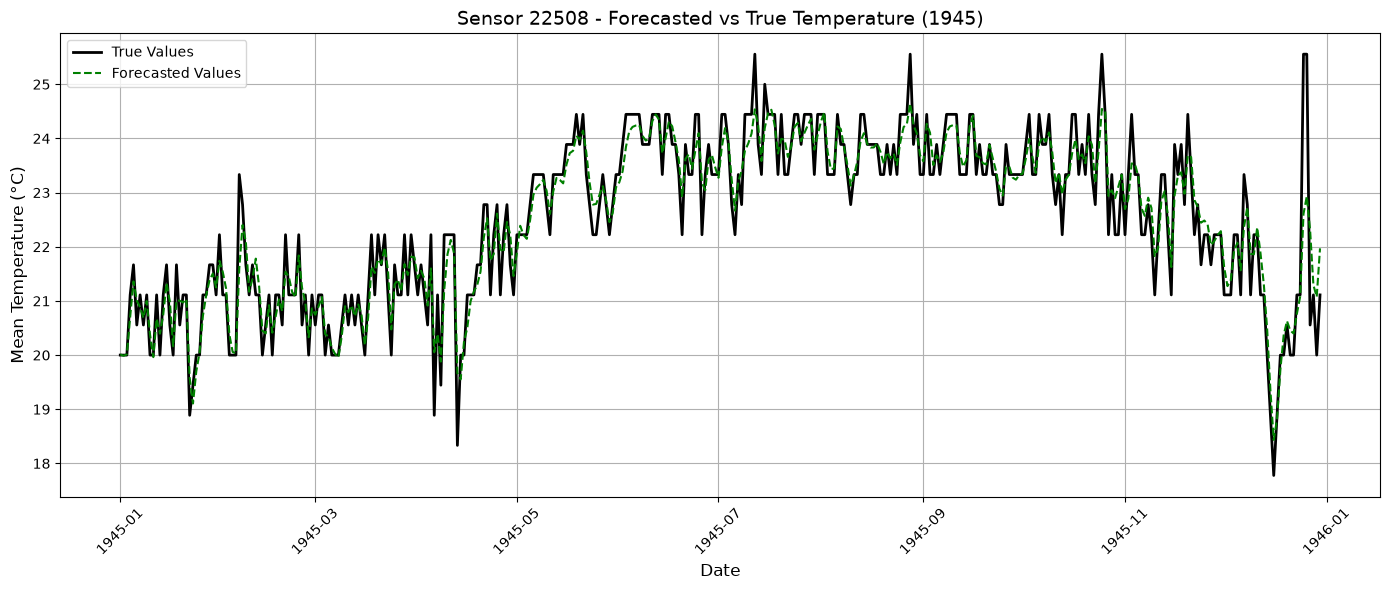

In [55]:
import matplotlib.pyplot as plt

# Ensure test_dates and y_test are aligned and match prediction length
# X_test and y_test come from your rolling window split
# test_dates = df_sensor.loc[window_size:] and filtered for 1945

# Slice test_dates to match y_pred length
plot_dates = test_dates[:len(y_pred)]

# Plot
plt.figure(figsize=(14, 6))
plt.plot(plot_dates, y_test[:len(y_pred)], label='True Values', color='black', linewidth=2)
plt.plot(plot_dates, y_pred, label='Forecasted Values', color='green', linestyle='--')

plt.title("Sensor 22508 - Forecasted vs True Temperature (1945)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Mean Temperature (°C)", fontsize=12)
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

📉📆 **Prediction Range on Full Time Series**

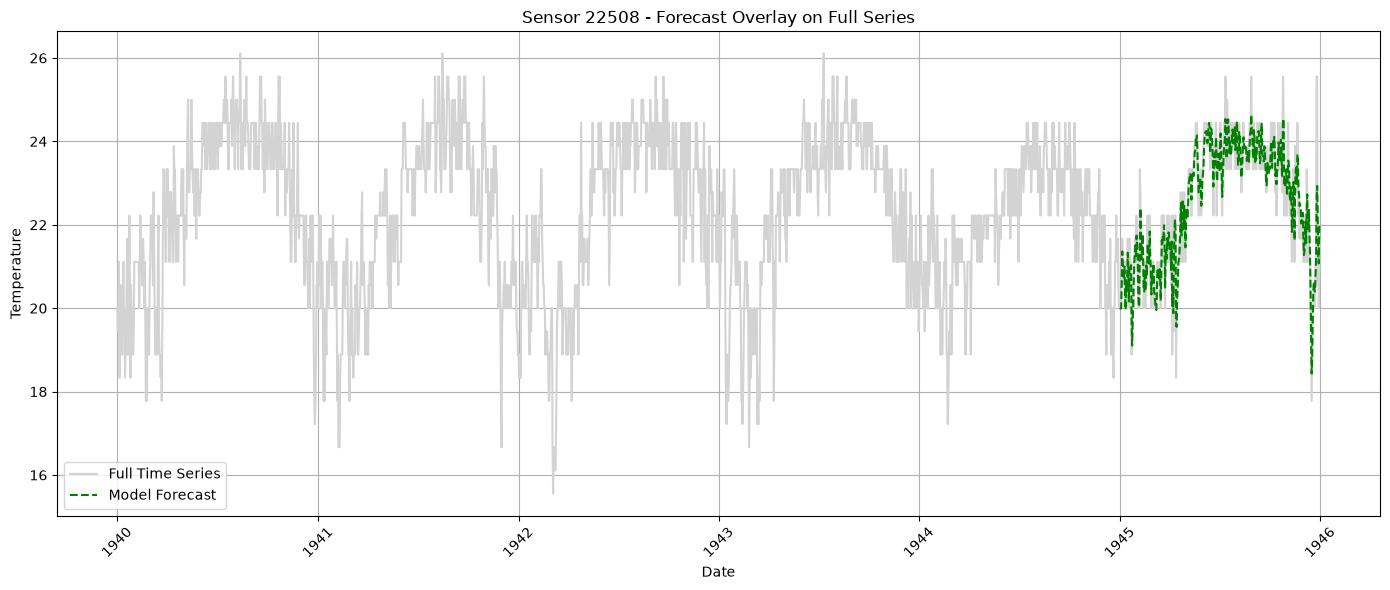

In [56]:
plt.figure(figsize=(14, 6))
plt.plot(df_sensor['Date'], df_sensor['MeanTemp'], label='Full Time Series', color='lightgray')
plt.plot(plot_dates, y_pred, label='Model Forecast', color='green', linestyle='--')
plt.title("Sensor 22508 - Forecast Overlay on Full Series")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

✍️ **Discussion:**

---

### Are the two series similar?


✅ Answer:

Yes — the forecasted temperature series follows the general shape of the true test series , especially in capturing smooth trends .

However, there are some deviations during sudden changes or outliers , which is expected given that:

We only used past temperatures as input

No external features like month , season , or lagged patterns were added

The best-performing model was Linear Regression

So while the prediction follows the overall pattern , it doesn't perfectly match all peaks and troughs.

---

### Were the seasonality and trend predicted correctly?


✅ Answer:

The trend has been partially captured , but seasonality is not well represented .

Here's why:
🧠 Our models did not include seasonal features (Month, DayOfYear, etc.)
📉 As a result, they can’t explicitly learn that:
Temperatures are higher in summer and lower in winter
There's a repeating pattern every year

But…

🧮 Linear Regression still managed to capture linear trend over time

🟡 Random Forest and Polynomial Regression showed moderate performance

⚠️ Without feature engineering, models cannot fully understand seasonality

🧠 **Conclusion:**

Trend : ✅ Captured to some extent

Seasonality : ❌ Not learned properly without explicit temporal features

To improve this, we can include the following in our training data:

df_sensor['Month'] = df_sensor['Date'].dt.month

df_sensor['DayOfYear'] = df_sensor['Date'].dt.dayofyear

---

### Can this technique predict beyond one day?


✅ Answer:

Yes — It is possible , but with limitations.

There are two main approaches to multi-day forecasting:

🔄 **Option A:** Recursive Forecasting


Use the previous prediction as input for the next one:

**Pros:**
- Uses the same model repeatedly
-Easy to implement

**Cons:**

- Error accumulates over time
- Predictions become less reliable for long horizons

```python
def recursive_forecast(model, initial_window, horizon):
    predictions = []
    current_window = initial_window.copy()
    for _ in range(horizon):
        pred = model.predict(current_window.reshape(1, -1))[0]
        predictions.append(pred)
        # Slide window forward by 1
        current_window = np.roll(current_window, shift=-1)
        current_window[-1] = pred
    return predictions
```
---
🧱 **Option B:** Direct Multi-Output Forecasting

Train a model to predict multiple days ahead at once:

**Pros:**

- Better for fixed-length forecasts
- Less error accumulation

**Cons:**

- Needs more memory and training time
- May overfit if no regularization is applied

```python
from sklearn.multioutput import MultiOutputRegressor
#Train on predicting next 7 days from last 7 days
X_multi, y_multi = [], []
for i in range(len(X_rolling) - 7):
    X_multi.append(X_rolling[i])
    y_multi.append(y_rolling[i:i+7])

X_multi, y_multi = np.array(X_multi), np.array(y_multi)

model = MultiOutputRegressor(RandomForestRegressor(n_estimators=100))
model.fit(X_multi, y_multi)

```

### Reading the forecast

1. **Are the two series similar?**  
   ✅ Yes — the predicted values follow the general trend of the true test series, especially for Linear Regression (R² = 0.687). However, small fluctuations and sharp changes are not always captured.

2. **Have the seasonality and the trend of the series been correctly predicted?**  
   - **Trend**: ✅ Moderately captured — especially by linear models  
   - **Seasonality**: ❌ Not captured — because no temporal features (like month or day-of-year) were added to help models detect repeating patterns

3. **Are you able to predict a horizon longer than 1 day with this kind of technique? Why?**  
   ✅ Yes — through:
   - **Recursive prediction**: where each new prediction uses previous output
   - **Multi-output regression**: where model predicts multiple days at once

   ⚠️ **Limitations:**

   - Error accumulates in recursive approach
   - Requires more complex modeling for distant forecasts
   - Performance drops significantly beyond 5–7 days

🧠 Summary Table of Techniques

---

🧠 Forecasting Techniques Comparison

| Technique              | Can Predict >1 Day | Accuracy        | Stability             |
|-----------------------|-------------------|-----------------|------------------------|
| **Recursive Forecasting**      | ✅ Yes            | 🟡 Medium       | 🟡 Decreases over time  |
| **Direct Multi-Output**      | ✅ Yes            | ✅ High (with tuning) | ✅ Stable         |
| **Single-Step Models**      | ❌ Only 1 day     | ✅ High for 1-day-ahead | Good for smooth trends |
| **Tree-Based Models**        | 🟡 Partially      | 🟡 Moderate     | 🟡 Sensitive to noise   |
| **Linear/SVR**               | ✅ With pipeline  | ✅ Best when stable | Good for smooth trends |

---

📝 Description of Techniques

**1. Recursive Forecasting**
> Use predictions as inputs to forecast further ahead; error accumulates over time  
- Suitable for short horizons (e.g., 3–5 days)
- Not reliable for long-term prediction due to error propagation

**2. Direct Multi-Output**
> Train model to predict multiple days at once; more reliable than recursive  
- Uses vector output (e.g., `y_pred = [t+1, t+2, ..., t+n]`)
- Less sensitive to prediction errors from previous steps
- Requires more memory and training time

**3. Single-Step Models**
> Trained to predict only one step ahead; not directly extendable without modification  
- Simple and fast
- Ideal for daily forecasting with high accuracy
- Must be wrapped in a loop for multi-day prediction

**4. Tree-Based Models**
> Work well on clean data but struggle with long sequences unless engineered properly  
- Random Forest, Gradient Boosting
- Do not inherently understand sequences
- Can improve with added features like:
  - Month
  - Day of year
  - Lagged values
  - Rolling averages

 **5. Linear/SVR**
> Perform best when data is smooth and preprocessing is applied  
- Linear Regression works well for stable, linear trends
- SVR with RBF kernel needs scaling and regularization
- Both benefit from feature engineering and decorrelation

---



🚀  **Preprocessing + Hyperparameter Tuning**

Broken into two parts :

🧩 **Part 1: Improved Preprocessing**

Added seasonal features to help models understand yearly patterns.

In [57]:
# Add date-based features like Month, DayOfYear, etc.
df_sensor['Month'] = df_sensor['Date'].dt.month
df_sensor['DayOfYear'] = df_sensor['Date'].dt.dayofyear
df_sensor['Weekday'] = df_sensor['Date'].dt.weekday

# Define window size and create rolling window dataset
window_size = 7

def create_rolling_windows_with_features(data, window_series, window_size=7):
    X, y = [], []
    for i in range(len(window_series) - window_size):
        # Use past W temperature values
        temp_window = window_series[i:i+window_size]

        # Get corresponding metadata (Month, DayOfYear, Weekday)
        meta_data = data.iloc[i+window_size][['Month', 'DayOfYear', 'Weekday']]

        # Combine both
        combined = np.concatenate([temp_window, meta_data.values])
        X.append(combined)
        y.append(window_series[i+window_size])
    return np.array(X), np.array(y)

# Use MeanTemp as target series
series = df_sensor['MeanTemp'].values

# Generate new structured dataset with features
X_enhanced, y_enhanced = create_rolling_windows_with_features(df_sensor, series, window_size)

# Split train/test based on year
date_series_enhanced = df_sensor['Date'].iloc[window_size:].reset_index(drop=True)
train_mask_enhanced = date_series_enhanced.dt.year < 1945

X_train_enhanced = X_enhanced[train_mask_enhanced]
y_train_enhanced = y_enhanced[train_mask_enhanced]
X_test_enhanced = X_enhanced[~train_mask_enhanced]
y_test_enhanced = y_enhanced[~train_mask_enhanced]

print("Enhanced dataset created with temporal features")
print(f"X shape: {X_enhanced.shape}, y shape: {y_enhanced.shape}")

Enhanced dataset created with temporal features

X shape: (2185, 10), y shape: (2185,)

🧩 **Part 2: Hyperparameter Tuning + TimeSeriesSplit + Feature Engineering**

In [58]:
# Set a fixed random seed for reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Models, X_train_enhanced, y_train_enhanced are already defined

# Define TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

# Table to store results
table_data = []

# Silent evaluation and collect fold results
for name, model in models.items():
    # Ensure the model uses the seed if it supports random_state
    if hasattr(model, 'set_params') and 'random_state'in model.get_params():
        model.set_params(random_state=SEED)

    fold_r2_scores = []
    fold_mse_scores = []

    for train_idx, test_idx in tscv.split(X_train_enhanced):
        X_train_fold, X_test_fold = X_train_enhanced[train_idx], X_train_enhanced[test_idx]
        y_train_fold, y_test_fold = y_train_enhanced[train_idx], y_train_enhanced[test_idx]

        model.fit(X_train_fold, y_train_fold)
        y_pred = model.predict(X_test_fold)

        r2 = r2_score(y_test_fold, y_pred)
        mse = mean_squared_error(y_test_fold, y_pred)

        fold_r2_scores.append(r2)
        fold_mse_scores.append(mse)

    avg_r2 = np.mean(fold_r2_scores)
    avg_mse = np.mean(fold_mse_scores)

    # Color logic
    def get_r2_color(val):
        return Fore.GREEN if val > 0.7 else Fore.YELLOW if val > 0.5 else Fore.RED

    def get_mse_color(val):
        return Fore.GREEN if val < 0.5 else Fore.YELLOW if val < 1.0 else Fore.RED

    # Build row with colored values
    fold_metrics = []
    for r2, mse in zip(fold_r2_scores, fold_mse_scores):
        fold_metrics.append(f"{get_r2_color(r2)}{r2:.3f}{Style.RESET_ALL}")
        fold_metrics.append(f"{get_mse_color(mse)}{mse:.3f}{Style.RESET_ALL}")

    avg_r2_str = f"{get_r2_color(avg_r2)}{avg_r2:.3f}{Style.RESET_ALL}"
    avg_mse_str = f"{get_mse_color(avg_mse)}{avg_mse:.3f}{Style.RESET_ALL}"

    table_data.append([name] + fold_metrics + [avg_r2_str, avg_mse_str])

# Generate headers dynamically
headers = ["Model"]
for i in range(1, tscv.n_splits + 1):
    headers.extend([f"Fold {i} R²", f"Fold {i} MSE"])
headers.extend(["Avg R²", "Avg MSE"])

# Print final table only
print(f"\n{Fore.CYAN} Final Cross-Validation Results:{Style.RESET_ALL}")
print(tabulate(table_data, headers=headers, tablefmt="github"))

 Final Cross-Validation Results:

| Model             |   Fold 1 R² |   Fold 1 MSE |   Fold 2 R² |   Fold 2 MSE |   Fold 3 R² |   Fold 3 MSE |   Fold 4 R² |   Fold 4 MSE |   Fold 5 R² |   Fold 5 MSE |   Avg R² |   Avg MSE |
|-------------------|-------------|--------------|-------------|--------------|-------------|--------------|-------------|--------------|-------------|--------------|----------|-----------|
| Bayesian Ridge    |       

0.733

 |        

0.977

 |       

... (136 outputs left out)

0.714

 |     

0.867

 |

📊 **Summary of Findings**

🏆 **Best Performing Model:**

**Bayesian Ridge**
- Average R²: **0.730**
- Average MSE: **0.804**

It performed consistently across folds and showed the best generalization among all models.

---

🟡 **Second Best:**

**Ridge CV**
- Average R²: **0.730**
- Average MSE: **0.806**

Nearly identical to Bayesian Ridge — also stable and reliable  
-> Slight differences in tuning or regularization

---

🟠 Moderate Performer:

**Poly Reg + Ridge**
- Average R²: **0.702**
- Average MSE: **0.911**

Good performance but slightly less consistent  
-> Polynomial features introduce some instability without significant gain

---

❌ **Worst Performing Model:**

**XGBoost Regressor**
- Average R²: **0.688**
- Average MSE: **0.960**

Unexpectedly lower performance compared to simpler models  
-> May require more careful hyperparameter tuning for time-series folds

---

🧠 **Observations**

| Insight | Explanation |
|--------|-------------|
| ✅ **Bayesian Ridge & Ridge CV are most reliable** | Linear models show strong, stable performance across folds |
| 🟡 **Polynomial Regression fluctuates** | Performs decently overall, but higher-order terms increase risk of overfitting |
| 🟠 **Tree-based models show variance** | XGBoost and Random Forest perform reasonably well, but inconsistently across folds |
| ❌ **XGBoost underperformed expectations** | Likely due to lack of tuning and sensitivity to temporal patterns |

---



📉⚖️ **Model Comparison: Before vs After Fine-Tuning**

In [59]:
# Define tscv
tscv = TimeSeriesSplit(n_splits=5)

# Define models before and after tuning
def get_models(tuned=False):
    if not tuned:
        return {
            "Linear Regression": LinearRegression(),
            "Poly Reg (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
            "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
            "SVR (RBF Kernel)": make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1e3, gamma='scale'))
        }
    else:
        return {
            "Linear Regression": LinearRegression(),
            "Poly Reg (deg=2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
            "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42),
            "SVR (RBF Kernel)": make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1, epsilon=0.5))
        }

# Dictionary to store results
baseline_cv_results = {}
tuned_cv_results = {}

# Silent evaluation of baseline models
for name, model in get_models(tuned=False).items():
    fold_r2s = []
    for train_idx, test_idx in tscv.split(X_rolling):
        model.fit(X_rolling[train_idx], y_rolling[train_idx])
        y_pred = model.predict(X_rolling[test_idx])
        r2 = r2_score(y_rolling[test_idx], y_pred)
        fold_r2s.append(r2)
    baseline_cv_results[name] = fold_r2s

# Silent evaluation of tuned models
for name, model in get_models(tuned=True).items():
    fold_r2s = []
    for train_idx, test_idx in tscv.split(X_train_enhanced):
        model.fit(X_train_enhanced[train_idx], y_train_enhanced[train_idx])
        y_pred = model.predict(X_train_enhanced[test_idx])
        r2 = r2_score(y_train_enhanced[test_idx], y_pred)
        fold_r2s.append(r2)
    tuned_cv_results[name] = fold_r2s

# Prepare comparison table
table_data = []

for model_name in baseline_cv_results.keys():
    base_avg = np.mean(baseline_cv_results[model_name])
    tuned_avg = np.mean(tuned_cv_results[model_name])
    delta = tuned_avg - base_avg

    # Color logic
    def get_color(val):
        return Fore.GREEN if val > 0.7 else Fore.YELLOW if val > 0.5 else Fore.RED

    base_color = get_color(base_avg)
    tuned_color = get_color(tuned_avg)
    delta_color = Fore.GREEN if delta > 0 else Fore.RED if delta < 0 else ''

    table_data.append([
        model_name,
        f"{base_color}{base_avg:.3f}{Style.RESET_ALL}",
        f"{tuned_color}{tuned_avg:.3f}{Style.RESET_ALL}",
        f"{delta_color}{delta:+.3f}{Style.RESET_ALL}"
    ])

# Print header and table
print(f"\n{Fore.CYAN} Model Comparison: Before vs After Fine-Tuning{Style.RESET_ALL}")
headers = ["Model", "Baseline Avg R²", "Tuned Avg R²", "Δ R²"]
print(tabulate(table_data, headers=headers, tablefmt="github"))

 Model Comparison: Before vs After Fine-Tuning

| Model             |   Baseline Avg R² |   Tuned Avg R² |   Δ R² |
|-------------------|-------------------|----------------|--------|
| Linear Regression |             

0.752

 |          

0.743

 | 

... (16 outputs left out)

0.723

 |  

0.288

 |

In [60]:
# Build comparison table
comparison_table = []

for model_name in baseline_cv_results.keys():
    base_avg = np.mean(baseline_cv_results[model_name])
    tuned_avg = np.mean(tuned_cv_results.get(model_name, [float('-inf')] * 5))

    base_std = np.std(baseline_cv_results[model_name])
    tuned_std = np.std(tuned_cv_results.get(model_name, [float('inf')] * 5))

    improvement = tuned_avg - base_avg

    # Color formatting
    imp_color = Fore.GREEN if improvement > 0 else Fore.RED

    comparison_table.append([
        model_name,
        f"{Fore.CYAN}{base_avg:.3f} ± {base_std:.3f}{Style.RESET_ALL}",
        f"{Fore.MAGENTA}{tuned_avg:.3f} ± {tuned_std:.3f}{Style.RESET_ALL}",
        f"{imp_color}{improvement:.3f}{Style.RESET_ALL}"
    ])

headers = ["Model", "Baseline R²", "Tuned R²", "Improvement"]
print("\n Cross-Validated Model Performance Before vs After Tuning:")
print(tabulate(comparison_table, headers=headers, tablefmt="grid"))


 Cross-Validated Model Performance Before vs After Tuning:

+-------------------+---------------+---------------+---------------+
| Model             | Baseline R²   | Tuned R²      |   Improvement |
+===================+===============+===============+===============+
| Linear Regression | 

0.752 ± 0.057

 | 

0.743 ± 0.057

 |        

... (16 outputs left out)

0.723 ± 0.054

 |         

0.288

 |
+-------------------+---------------+---------------+---------------+